# EDA of the current sample: creators, videos, tagged subset, traits

In [1]:
"""Settings. Every count comes from the snapshot on SNAPSHOT_DATE (video_daily_snapshots and
channel_daily_snapshots), so rerunning later reproduces these numbers; metadata (title, category,
duration) comes from youtube.videos. Tags are restricted to videos still tracked and tagged by the
end of SNAPSHOT_DATE."""
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.cloud import bigquery
from googleapiclient.discovery import build
from scipy import stats

sys.path.insert(0, os.path.abspath("../src"))
import config
from traits import get_traits

SNAPSHOT_DATE = "2026-11-04"
FIRST_DAILY_DATE = "2026-10-21"
SHORTS_MAX_SECONDS = 180
SPARSE_LEVEL_MIN_VIDEOS = 20
NEAR_CONSTANT_HIGH = 0.90
NEAR_CONSTANT_LOW = 0.05
FIG_DIR = os.path.abspath("../docs/figures")
os.makedirs(FIG_DIR, exist_ok=True)

ORG_CHANNELS = {
    "Architectural Digest": "magazine brand (Conde Nast)",
    "First We Feast": "media company (Complex)",
    "Cut": "production company",
    "Jubilee": "production company",
    "triple j": "public radio station (ABC Australia)",
    "THE RACE": "motorsport news outlet",
    "CrashCourse": "educational production company",
    "The B1M": "video publisher with staff",
}

RED, ACCENT, GRAY, INK, BLUE = "#990000", "#C44545", "#C9C9C9", "#1A1A1A", "#3B6EA5"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

## Load

In [2]:
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)
dataset = f"{config.GCP_PROJECT_ID}.{config.BQ_DATASET}"

df_channels = client.query(f"""
    SELECT c.id AS channel_id, c.snippet_title AS channel_title, c.team_genre, c.team_size,
        c.snippet_country AS country, DATE(TIMESTAMP(c.snippet_publishedAt)) AS channel_created,
        s.subscriber_count AS subs, s.view_count AS channel_views, s.video_count AS channel_video_count
    FROM `{dataset}.channels` c
    LEFT JOIN `{dataset}.channel_daily_snapshots` s ON s.channel_id = c.id AND s.snapshot_date = DATE("{SNAPSHOT_DATE}")
""").to_dataframe()

df_channel_history = client.query(f"""
    SELECT channel_id, MIN(snapshot_date) AS first_snapshot,
        ARRAY_AGG(subscriber_count ORDER BY snapshot_date LIMIT 1)[OFFSET(0)] AS subs_first,
        ARRAY_AGG(IF(snapshot_date >= DATE("{FIRST_DAILY_DATE}"), subscriber_count, NULL) IGNORE NULLS
                  ORDER BY snapshot_date LIMIT 1)[OFFSET(0)] AS subs_daily_start,
        MIN(IF(snapshot_date >= DATE("{FIRST_DAILY_DATE}"), snapshot_date, NULL)) AS daily_start
    FROM `{dataset}.channel_daily_snapshots`
    WHERE snapshot_date <= DATE("{SNAPSHOT_DATE}")
    GROUP BY channel_id
""").to_dataframe()
df_channels = df_channels.merge(df_channel_history, on="channel_id", how="left")
count_columns = ["subs", "channel_views", "channel_video_count", "subs_first", "subs_daily_start"]
df_channels[count_columns] = df_channels[count_columns].astype(float)

df_videos = client.query(f"""
    SELECT v.id, v.snippet_channelId AS channel_id, v.snippet_channelTitle AS channel_title,
        v.snippet_title AS title, TIMESTAMP(v.snippet_publishedAt) AS published_at, v.snippet_categoryId AS category_id,
        v.duration_seconds, v.contentDetails_caption = 'true' AS has_captions,
        v.paidProductPlacementDetails_hasPaidProductPlacement AS paid_placement,
        ARRAY_LENGTH(SPLIT(NULLIF(v.snippet_tags, ''), '|')) AS tag_count,
        s.age_days, s.view_count AS views, s.like_count AS likes, s.comment_count AS comments
    FROM `{dataset}.videos` v
    JOIN `{dataset}.video_daily_snapshots` s ON s.video_id = v.id AND s.snapshot_date = DATE("{SNAPSHOT_DATE}")
    WHERE s.is_available
""").to_dataframe()
numeric_columns = ["duration_seconds", "tag_count", "age_days", "views", "likes", "comments"]
df_videos[numeric_columns] = df_videos[numeric_columns].astype(float)
df_videos["paid_placement"] = df_videos["paid_placement"].astype(bool)
df_videos["has_captions"] = df_videos["has_captions"].astype(bool)

df_tags = client.query(f"""
    SELECT * FROM `{dataset}.llm_tagged`
    WHERE tagged_at < TIMESTAMP_ADD(TIMESTAMP("{SNAPSHOT_DATE}"), INTERVAL 1 DAY)
    QUALIFY ROW_NUMBER() OVER (PARTITION BY id ORDER BY tagged_at) = 1
""").to_dataframe()
tag_rows_all = len(df_tags)
df_tags = df_tags[df_tags["id"].isin(df_videos["id"])].reset_index(drop=True)

traits = get_traits()
trait_columns = [trait["column"] for trait in traits]
trait_category = {trait["column"]: trait["category"] for trait in traits}
trait_scale = {trait["column"]: trait["scale"] for trait in traits}
trait_name = {trait["column"]: trait["name"] for trait in traits}
df_tags[trait_columns] = df_tags[trait_columns].astype(int)

print(f"channels on the sheet: {len(df_channels)}; with a {SNAPSHOT_DATE} snapshot: {df_channels['subs'].notna().sum()}")
print(f"videos available on {SNAPSHOT_DATE}: {len(df_videos):,} from {df_videos['channel_id'].nunique()} channels")
print(f"llm_tagged rows (deduplicated, tagged by {SNAPSHOT_DATE}): {tag_rows_all:,}; on tracked videos: {len(df_tags):,}")
print(f"traits: {len(traits)} ({sum(trait_scale[column] == 'linear' for column in trait_columns)} linear 0-4, "
      f"{sum(trait_scale[column] == 'binary' for column in trait_columns)} binary)")

/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


channels on the sheet: 53; with a 2026-11-04 snapshot: 53
videos available on 2026-11-04: 13,717 from 52 channels
llm_tagged rows (deduplicated, tagged by 2026-11-04): 2,939; on tracked videos: 2,788
traits: 79 (75 linear 0-4, 4 binary)


In [3]:
"""Genre = YouTube category (snippet.categoryId, chosen by the uploader), named via videoCategories.list.
A channel's YouTube genre is its most common category over the past year."""
youtube = build("youtube", "v3", developerKey=config.YOUTUBE_API_KEY)
category_titles = {item["id"]: item["snippet"]["title"]
                   for item in youtube.videoCategories().list(part="snippet", regionCode="US").execute()["items"]}

df_videos["genre"] = df_videos["category_id"].map(category_titles)
df_videos["is_short"] = df_videos["duration_seconds"] <= SHORTS_MAX_SECONDS
df_videos["log_views"] = np.log10(df_videos["views"] + 1)
df_videos["like_rate"] = df_videos["likes"] / df_videos["views"].where(df_videos["views"] > 0)
df_videos["comment_rate"] = df_videos["comments"] / df_videos["views"].where(df_videos["views"] > 0)
df_videos["published_pt"] = df_videos["published_at"].dt.tz_convert("America/Los_Angeles")
df_videos["weekday"] = df_videos["published_pt"].dt.day_name()
df_videos["hour_pt"] = df_videos["published_pt"].dt.hour
df_videos["is_tagged"] = df_videos["id"].isin(df_tags["id"])
df_videos = df_videos.merge(df_channels[["channel_id", "subs"]], on="channel_id", how="left")
df_videos["views_per_sub"] = df_videos["views"] / df_videos["subs"]
df_videos["views_pct_global"] = df_videos["views"].rank(pct=True)
df_videos["views_pct_in_channel"] = df_videos.groupby("channel_id")["views"].rank(pct=True)
print(f"Shorts proxy: duration <= {SHORTS_MAX_SECONDS} s (the public API has no Shorts flag).")
print(f"missing likes: {df_videos['likes'].isna().sum()}, missing comments: {df_videos['comments'].isna().sum()}, zero views: {(df_videos['views'] == 0).sum()}")

Shorts proxy: duration <= 180 s (the public API has no Shorts flag).
missing likes: 2, missing comments: 1, zero views: 1


## 1. Creators

In [4]:
df_channel_stats = df_videos.groupby("channel_id").agg(
    uploads_past_year=("id", "size"),
    shorts_share=("is_short", "mean"),
    median_views=("views", "median"),
    median_views_per_sub=("views_per_sub", "median"),
    tagged_videos=("is_tagged", "sum"),
    yt_genre=("genre", lambda genres: genres.value_counts().idxmax()),
).reset_index()
df_creators = df_channels.merge(df_channel_stats, on="channel_id", how="left")
df_creators["uploads_past_year"] = df_creators["uploads_past_year"].fillna(0).astype(int)
df_creators["tagged_videos"] = df_creators["tagged_videos"].fillna(0).astype(int)
df_creators["size_tier"] = pd.cut(df_creators["subs"], bins=[0, 1e6, 1e7, 1e8, 1e10],
                                  labels=["<1M", "1-10M", "10-100M", "100M+"], right=False)
df_creators["org_type"] = df_creators["channel_title"].map(ORG_CHANNELS).fillna("")
df_creators["sub_growth_pct"] = 100 * (df_creators["subs"] / df_creators["subs_daily_start"] - 1)
df_creators = df_creators.sort_values("subs", ascending=False).reset_index(drop=True)
df_creators[["channel_title", "subs", "size_tier", "yt_genre", "team_genre", "uploads_past_year", "shorts_share",
             "median_views", "median_views_per_sub", "tagged_videos", "first_snapshot", "sub_growth_pct", "org_type"]].round(3)

,channel_title,subs,size_tier,yt_genre,team_genre,uploads_past_year,shorts_share,median_views,median_views_per_sub,tagged_videos,first_snapshot,sub_growth_pct,org_type
0,MrBeast,525000000.0,100M+,Entertainment,,101,0.743,146018555.0,0.278,54,2026-10-15,0.575,
1,Mark Rober,85600000.0,10-100M,Science & Technology,Science & Engineering,45,0.822,17026648.0,0.199,45,2026-10-15,1.542,
2,Dude Perfect,62800000.0,10-100M,Sports,Sports,156,0.878,4076377.0,0.065,72,2026-10-15,0.000,
3,Nick DiGiovanni,48200000.0,10-100M,People & Blogs,Food & Cooking,129,0.891,35413186.0,0.735,51,2026-10-15,1.048,
4,jacksepticeye,31100000.0,10-100M,Gaming,Gaming,82,0.024,2151067.0,0.069,8,2026-10-15,0.000,
5,Kurzgesagt – In a Nutshell,25800000.0,10-100M,Education,Education,84,0.726,2443085.0,0.095,54,2026-10-15,0.389,
6,Marques Brownlee,21400000.0,10-100M,Science & Technology,,94,0.298,5384576.5,0.252,57,2026-10-15,0.000,
7,Veritasium,21400000.0,10-100M,Education,Education,87,0.621,4501216.0,0.210,55,2026-10-15,0.000,
8,Good Mythical Morning,19800000.0,10-100M,Entertainment,Comedy,438,0.400,1073178.5,0.054,79,2026-10-15,0.000,
9,CrashCourse,17300000.0,10-100M,Education,,77,0.182,49223.0,0.003,57,2026-10-15,0.581,educational production company


In [5]:
print(f"subscribers: median {df_creators['subs'].median() / 1e6:.2f}M, mean {df_creators['subs'].mean() / 1e6:.1f}M, "
      f"min {df_creators['subs'].min():,.0f}, max {df_creators['subs'].max():,.0f}")
print(f"MrBeast alone = {df_creators['subs'].max() / df_creators['subs'].sum():.0%} of all subscribers in the sample")
print("\nsize tiers:")
print(df_creators["size_tier"].value_counts(sort=False).to_string())
print("\nfirst snapshot (= when the channel joined the sheet):")
print(df_creators["first_snapshot"].value_counts().sort_index().to_string())
print("added after the original list:", df_creators.loc[df_creators["first_snapshot"] > df_creators["first_snapshot"].min(), "channel_title"].tolist())
print("\nno uploads in the past year:", df_creators.loc[df_creators["uploads_past_year"] == 0, "channel_title"].tolist())
print("fewer than 20 uploads in the past year:",
      df_creators.loc[df_creators["uploads_past_year"].between(1, 19), ["channel_title", "uploads_past_year"]].values.tolist())
print("\nuploads past year: median", df_creators["uploads_past_year"].median(), "| max",
      df_creators["uploads_past_year"].max(), df_creators.loc[df_creators["uploads_past_year"].idxmax(), "channel_title"])
print("\norganisations rather than independent creators (team judgment, to confirm):", len(ORG_CHANNELS), "channels,",
      df_creators.loc[df_creators["org_type"] != "", "uploads_past_year"].sum(), "videos,",
      df_creators.loc[df_creators["org_type"] != "", "tagged_videos"].sum(), "tagged")
print("channels with no team genre on the sheet:", df_creators["team_genre"].fillna("").eq("").sum())

subscribers: median 4.92M, mean 20.0M, min 9,910, max 525,000,000
MrBeast alone = 50% of all subscribers in the sample

size tiers:
size_tier
<1M         9
1-10M      27
10-100M    16
100M+       1

first snapshot (= when the channel joined the sheet):
first_snapshot
2026-10-15    46
2026-10-21     6
2026-10-27     1
added after the original list: ['Tom Scott', 'Midwest Safety', 'Hasan Minhaj', 'Kelly Wakasa', 'SauccEats', 'Wayne Hu', 'Not My Business']

no uploads in the past year: ['Wayne Hu']
fewer than 20 uploads in the past year: [['emma chamberlain', 1], ['Evan and Katelyn', 12], ['Breaking Taps', 8], ['Leadhead', 6], ['Not My Business', 2]]

uploads past year: median 101.0 | max 1645 Club 520 Podcast

organisations rather than independent creators (team judgment, to confirm): 8 channels, 4591 videos, 667 tagged
channels with no team genre on the sheet: 17


In [6]:
"""Median views per subscriber per channel: how much of its audience a typical video reaches.
Values far below the rest mean the channel's videos are not what its subscribers come for (or the
subscriber count is legacy)."""
log_vps = np.log10(df_creators["median_views_per_sub"].dropna())
low_cut = 10 ** (log_vps.median() - 2 * stats.median_abs_deviation(log_vps, scale="normal"))
high_cut = 10 ** (log_vps.median() + 2 * stats.median_abs_deviation(log_vps, scale="normal"))
print(f"median views/sub across channels: {df_creators['median_views_per_sub'].median():.3f} "
      f"(robust 2-sigma band {low_cut:.4f} to {high_cut:.3f})")
df_creators.loc[(df_creators["median_views_per_sub"] < low_cut) | (df_creators["median_views_per_sub"] > high_cut),
                ["channel_title", "subs", "uploads_past_year", "shorts_share", "median_views", "median_views_per_sub"]]

median views/sub across channels: 0.127 (robust 2-sigma band 0.0120 to 1.342)


,channel_title,subs,uploads_past_year,shorts_share,median_views,median_views_per_sub
9,CrashCourse,17300000.0,77,0.181818,49223.0,0.002845
10,First We Feast,15900000.0,1057,0.860927,116735.0,0.007342
12,Cut,12400000.0,292,0.890411,74125.0,0.005978
15,Jubilee,11000000.0,871,0.853042,58623.0,0.005329
18,Architectural Digest,8050000.0,588,0.846939,41872.0,0.005201
22,Ali Abdaal,6710000.0,303,0.841584,33000.0,0.004918
34,triple j,2080000.0,796,0.634422,11697.0,0.005624
40,SauccEats,1620000.0,57,0.964912,3174967.0,1.959856
52,Not My Business,9910.0,2,0.000000,337826.5,34.089455


In [7]:
"""YouTube genre (uploader's category, most common per channel) vs the team's genre label from the sheet."""
pd.crosstab(df_creators["team_genre"].replace("", np.nan).fillna("(blank)"), df_creators["yt_genre"].fillna("(no videos)"))

yt_genre,(no videos),Autos & Vehicles,Comedy,Education,Entertainment,Gaming,Howto & Style,News & Politics,People & Blogs,Pets & Animals,Science & Technology,Sports,Travel & Events
team_genre,,,,,,,,,,,,,
(blank),1,1,1,3,4,0,1,1,2,0,2,1,0
ASMR,0,0,0,0,1,0,0,0,0,0,0,0,0
Beauty,0,0,0,0,0,0,1,0,0,0,0,0,0
Business,0,0,0,1,0,0,0,0,0,0,0,0,0
Comedy,0,0,0,0,1,1,0,0,0,0,0,0,0
DIY,0,0,0,0,0,0,1,0,0,0,0,0,0
Education,0,0,0,2,1,0,0,0,0,0,0,0,0
Fashion,0,0,0,1,0,0,0,0,0,0,0,0,0
Finance,0,0,0,1,0,0,0,0,1,0,0,0,0


In [8]:
"""Subscriber growth over the daily window. The Data API rounds subscriber counts to 3 significant
figures, so small channels' growth is coarse and large channels often show exactly 0%."""
df_growth = df_creators.dropna(subset=["sub_growth_pct"])
window_days = (pd.Timestamp(SNAPSHOT_DATE) - pd.to_datetime(df_growth["daily_start"])).dt.days
print(f"{len(df_growth)} channels with a daily start and a {SNAPSHOT_DATE} value; window {window_days.min()}-{window_days.max()} days")
print(f"exactly 0% change (rounding): {(df_growth['sub_growth_pct'] == 0).sum()}; negative: {(df_growth['sub_growth_pct'] < 0).sum()}")
print(f"median growth {df_growth['sub_growth_pct'].median():.2f}%")
df_growth.sort_values("sub_growth_pct", ascending=False)[["channel_title", "subs_daily_start", "subs", "sub_growth_pct", "daily_start"]].head(8)

53 channels with a daily start and a 2026-11-04 value; window 8-14 days
exactly 0% change (rounding): 23; negative: 0
median growth 0.21%


,channel_title,subs_daily_start,subs,sub_growth_pct,daily_start
52,Not My Business,7630.0,9910.0,29.882045,2026-10-27
28,CarterPCs,3870000.0,3980000.0,2.842377,2026-10-21
40,SauccEats,1580000.0,1620000.0,2.531646,2026-10-21
1,Mark Rober,84300000.0,85600000.0,1.542112,2026-10-21
37,Slushy Noobz,1680000.0,1700000.0,1.190476,2026-10-21
3,Nick DiGiovanni,47700000.0,48200000.0,1.048218,2026-10-21
16,Max the Meat Guy,10300000.0,10400000.0,0.970874,2026-10-21
44,Taylor Bell,963000.0,972000.0,0.934579,2026-10-21


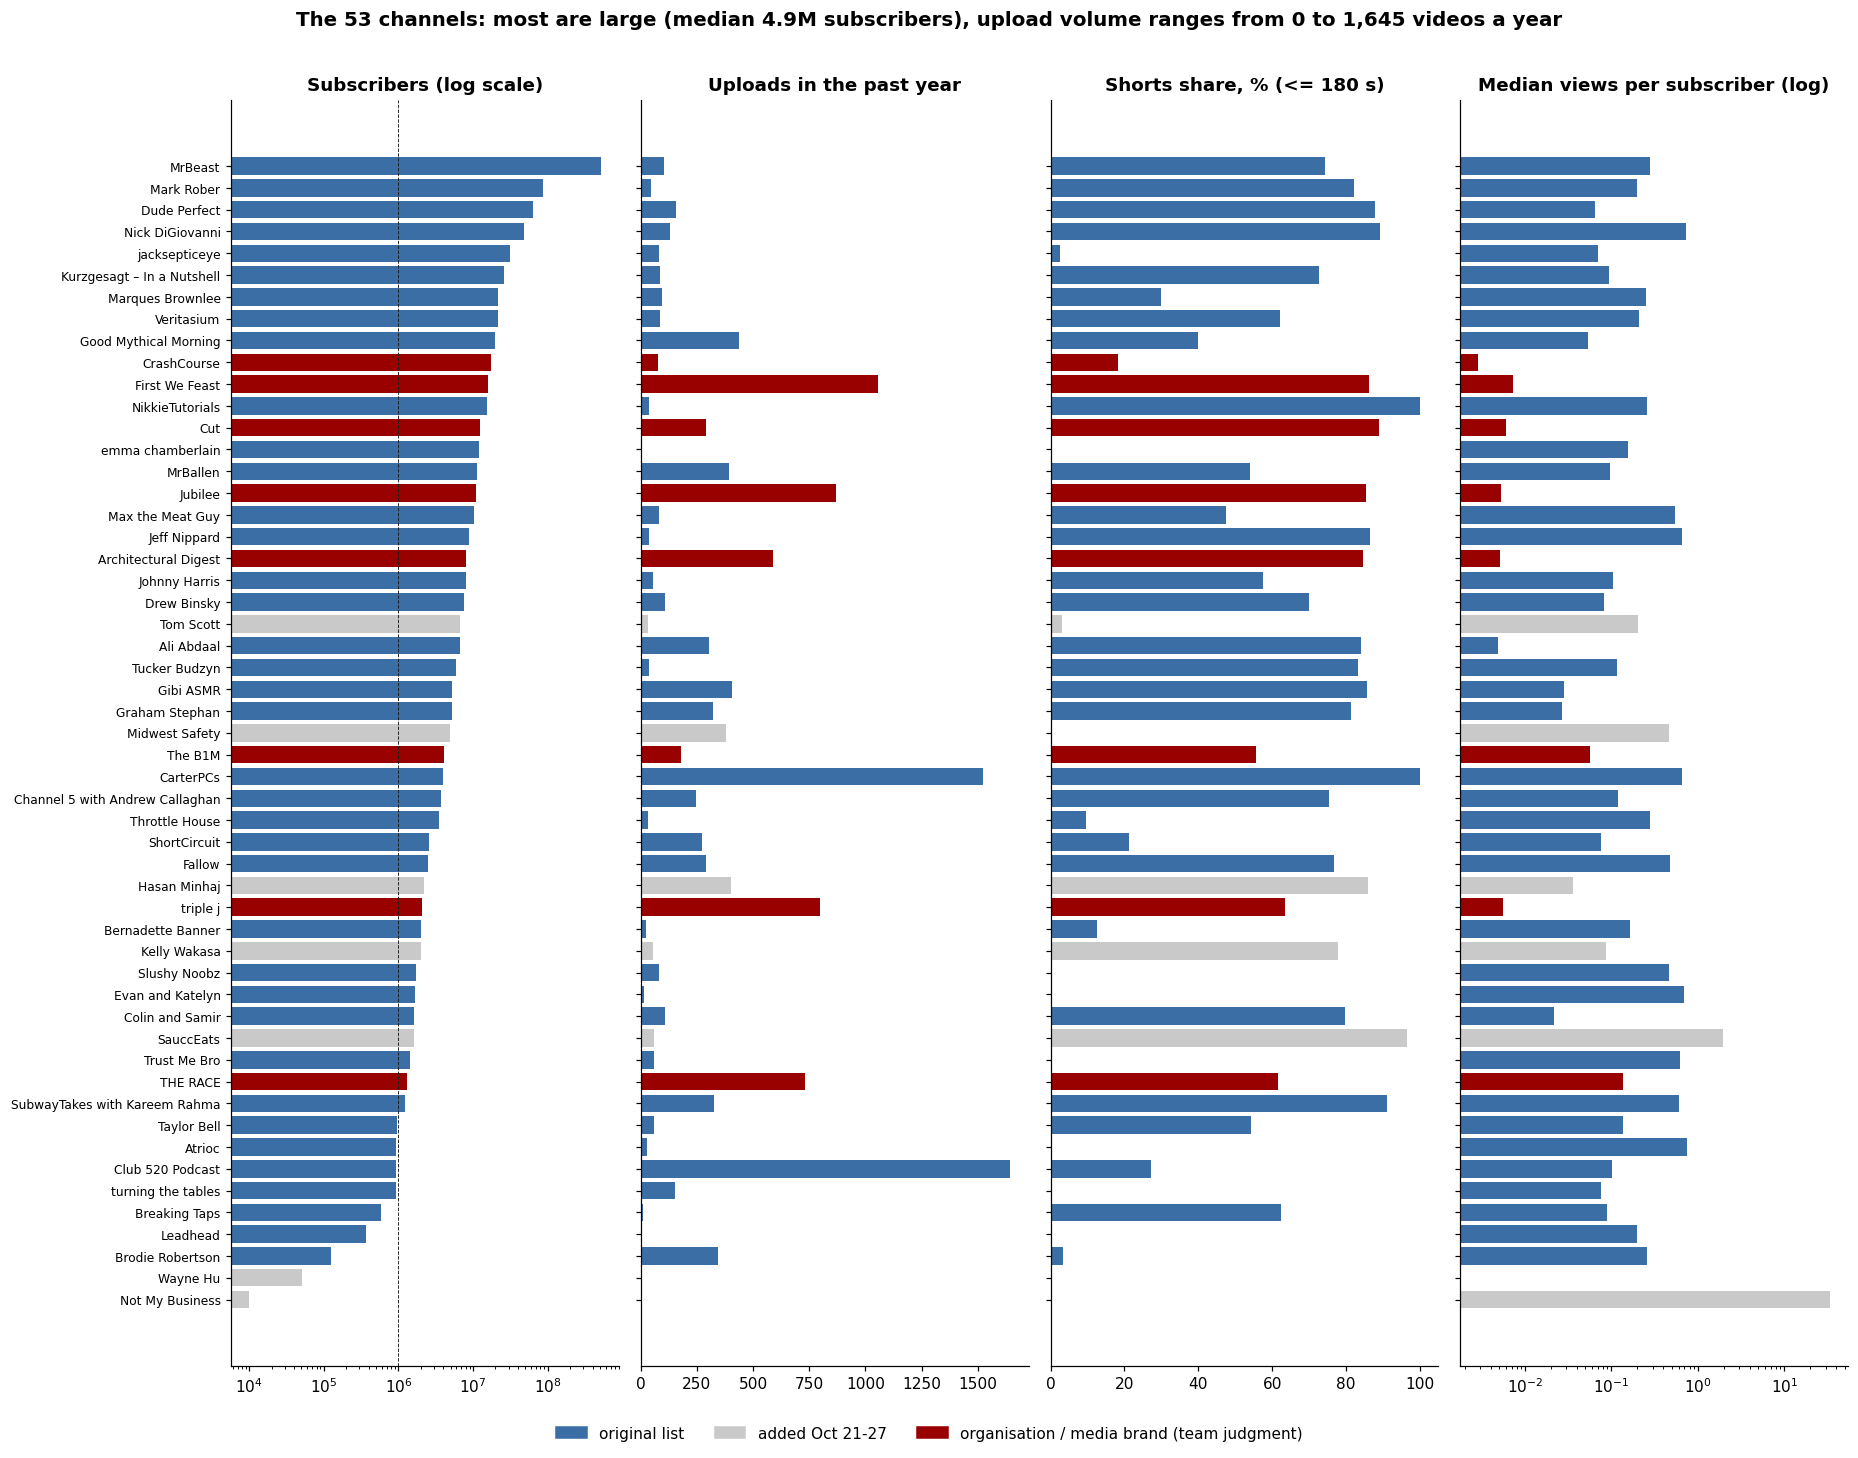

In [9]:
def flag_color(row):
    """Red = organisation (not an independent creator), gray = joined after the original list, blue = other."""
    if row["org_type"] != "":
        return RED
    if row["first_snapshot"] > df_creators["first_snapshot"].min():
        return GRAY
    return BLUE


df_plot = df_creators.sort_values("subs").reset_index(drop=True)
bar_colors = [flag_color(row) for _, row in df_plot.iterrows()]
positions = np.arange(len(df_plot))

fig, axes = plt.subplots(1, 4, figsize=(17, 13), sharey=True)
axes[0].barh(positions, df_plot["subs"], color=bar_colors)
axes[0].set_xscale("log")
axes[0].set_title("Subscribers (log scale)", fontweight="bold")
axes[0].axvline(1e6, color=INK, lw=0.6, ls="--")
axes[0].set_yticks(positions, df_plot["channel_title"], fontsize=8)

axes[1].barh(positions, df_plot["uploads_past_year"], color=bar_colors)
axes[1].set_title("Uploads in the past year", fontweight="bold")

axes[2].barh(positions, df_plot["shorts_share"].fillna(0) * 100, color=bar_colors)
axes[2].set_title(f"Shorts share, % (<= {SHORTS_MAX_SECONDS} s)", fontweight="bold")

axes[3].barh(positions, df_plot["median_views_per_sub"].fillna(np.nan), color=bar_colors)
axes[3].set_xscale("log")
axes[3].set_title("Median views per subscriber (log)", fontweight="bold")

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in [BLUE, GRAY, RED]]
fig.legend(legend_handles, ["original list", "added Oct 21-27", "organisation / media brand (team judgment)"],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle(f"The 53 channels: most are large (median {df_creators['subs'].median() / 1e6:.1f}M subscribers), "
             f"upload volume ranges from 0 to {df_creators['uploads_past_year'].max():,} videos a year",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(rect=[0, 0.02, 1, 0.99])
fig.savefig(f"{FIG_DIR}/eda_creators.png")
plt.show()

## 2. Videos

In [10]:
df_videos[["views", "likes", "comments", "like_rate", "comment_rate", "duration_seconds", "age_days"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).T.round(4)

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
views,13717.0,3.701265e+06,3.202632e+07,0.0000,22546.0000,52730.0000,221991.0000,1.266667e+06,4.172107e+06,5.814121e+07,1.230535e+09
likes,13715.0,6.780815e+04,3.466369e+05,0.0000,395.0000,1165.5000,5435.0000,3.783150e+04,1.241124e+05,9.620031e+05,1.128978e+07
comments,13716.0,1.990914e+03,1.775092e+04,0.0000,12.0000,53.0000,320.0000,1.295000e+03,3.784000e+03,2.250265e+04,1.417061e+06
like_rate,13714.0,2.810000e-02,1.540000e-02,0.0006,0.0118,0.0164,0.0245,3.710000e-02,4.970000e-02,7.250000e-02,1.312000e-01
comment_rate,13715.0,1.800000e-03,3.100000e-03,0.0000,0.0002,0.0004,0.0009,2.100000e-03,3.800000e-03,1.580000e-02,6.240000e-02
duration_seconds,13717.0,6.352797e+02,1.338718e+03,0.0000,30.0000,45.0000,87.0000,6.950000e+02,1.770000e+03,5.852080e+03,3.652500e+04
age_days,13717.0,1.907412e+02,1.096881e+02,0.0204,38.5011,98.0118,189.9576,2.820027e+02,3.445651e+02,3.801659e+02,3.852906e+02


In [11]:
print(f"Shorts share (<= {SHORTS_MAX_SECONDS} s): {df_videos['is_short'].mean():.1%}; <= 60 s: {(df_videos['duration_seconds'] <= 60).mean():.1%}; "
      f"> 30 min: {(df_videos['duration_seconds'] > 1800).mean():.1%}")
print(f"has captions: {df_videos['has_captions'].mean():.1%}; paid placement: {df_videos['paid_placement'].mean():.1%}")
print("\nvideos by YouTube genre:")
print(df_videos["genre"].value_counts().to_string())
print("\nweekday (PT):")
print(df_videos["weekday"].value_counts().to_string())

Shorts share (<= 180 s): 64.1%; <= 60 s: 36.5%; > 30 min: 9.7%
has captions: 14.1%; paid placement: 6.4%

videos by YouTube genre:
genre
Entertainment           5198
People & Blogs          2615
Sports                  2289
Education               1227
Science & Technology     763
Comedy                   730
News & Politics          421
Gaming                   159
Howto & Style            133
Travel & Events          108
Pets & Animals            36
Autos & Vehicles          31
Music                      7

weekday (PT):
weekday
Thursday     2385
Wednesday    2302
Monday       2098
Friday       2028
Tuesday      1998
Saturday     1519
Sunday       1387


In [12]:
"""Concentration: share of all videos and of all views held by the top channels."""
df_concentration = df_creators[df_creators["uploads_past_year"] > 0][["channel_title", "uploads_past_year"]].copy()
df_concentration = df_concentration.merge(
    df_videos.groupby("channel_title")["views"].sum().rename("total_views").reset_index(), on="channel_title")
df_concentration = df_concentration.sort_values("uploads_past_year", ascending=False).reset_index(drop=True)
df_concentration["video_share"] = df_concentration["uploads_past_year"] / df_concentration["uploads_past_year"].sum()
df_concentration["view_share"] = df_concentration["total_views"] / df_concentration["total_views"].sum()
for top_n in [1, 3, 5, 10]:
    print(f"top {top_n:>2} channels by uploads hold {df_concentration['video_share'].head(top_n).sum():.1%} of videos")
df_by_views = df_concentration.sort_values("total_views", ascending=False)
for top_n in [1, 3, 5]:
    print(f"top {top_n} channels by views hold {df_by_views['view_share'].head(top_n).sum():.1%} of all views "
          f"({', '.join(df_by_views['channel_title'].head(top_n))})")
hhi = (df_concentration["video_share"] ** 2).sum()
print(f"video HHI {hhi:.3f} -> effective number of channels {1 / hhi:.1f} (of {len(df_concentration)})")
df_concentration.head(10).round(3)

top  1 channels by uploads hold 12.0% of videos
top  3 channels by uploads hold 30.8% of videos
top  5 channels by uploads hold 43.0% of videos
top 10 channels by uploads hold 61.7% of videos
top 1 channels by views hold 48.3% of all views (MrBeast)
top 3 channels by views hold 74.0% of all views (MrBeast, CarterPCs, Nick DiGiovanni)
top 5 channels by views hold 79.5% of all views (MrBeast, CarterPCs, Nick DiGiovanni, Mark Rober, Dude Perfect)
video HHI 0.054 -> effective number of channels 18.5 (of 52)


,channel_title,uploads_past_year,total_views,video_share,view_share
0,Club 520 Podcast,1645,2.492950e+08,0.120,0.005
1,CarterPCs,1523,6.651679e+09,0.111,0.131
2,First We Feast,1057,7.922757e+08,0.077,0.016
3,Jubilee,871,2.869075e+08,0.063,0.006
4,triple j,796,5.364214e+07,0.058,0.001
5,THE RACE,730,1.694911e+08,0.053,0.003
6,Architectural Digest,588,1.236111e+08,0.043,0.002
7,Good Mythical Morning,438,5.286228e+08,0.032,0.010
8,Gibi ASMR,407,8.889765e+07,0.030,0.002
9,Hasan Minhaj,403,8.893996e+07,0.029,0.002


In [13]:
"""Views vs subscribers, log-log, at the video and channel level."""
df_positive = df_videos[(df_videos["views"] > 0) & df_videos["subs"].notna()]
video_rho = stats.spearmanr(df_positive["subs"], df_positive["views"]).statistic
df_channel_level = df_creators.dropna(subset=["median_views"])
channel_r = np.corrcoef(np.log10(df_channel_level["subs"]), np.log10(df_channel_level["median_views"]))[0, 1]
slope, intercept = np.polyfit(np.log10(df_channel_level["subs"]), np.log10(df_channel_level["median_views"]), 1)
print(f"video level: Spearman(views, subs) = {video_rho:.2f} (n = {len(df_positive):,})")
print(f"channel level: Pearson r(log subs, log median views) = {channel_r:.2f}, slope {slope:.2f} (n = {len(df_channel_level)})")

share_between = df_videos.groupby("channel_id")["log_views"].transform("mean").var() / df_videos["log_views"].var()
print(f"share of log-views variance that is between channels: {share_between:.0%}")

print("\nlike rate and comment rate by format (median):")
print(df_videos.groupby("is_short")[["like_rate", "comment_rate", "views"]].median().rename(index={False: "long", True: "short"}).round(4).to_string())

video level: Spearman(views, subs) = 0.27 (n = 13,716)
channel level: Pearson r(log subs, log median views) = 0.57, slope 0.65 (n = 52)
share of log-views variance that is between channels: 68%

like rate and comment rate by format (median):
          like_rate  comment_rate     views
is_short                                   
long         0.0205        0.0021  275599.0
short        0.0274        0.0006  189718.5


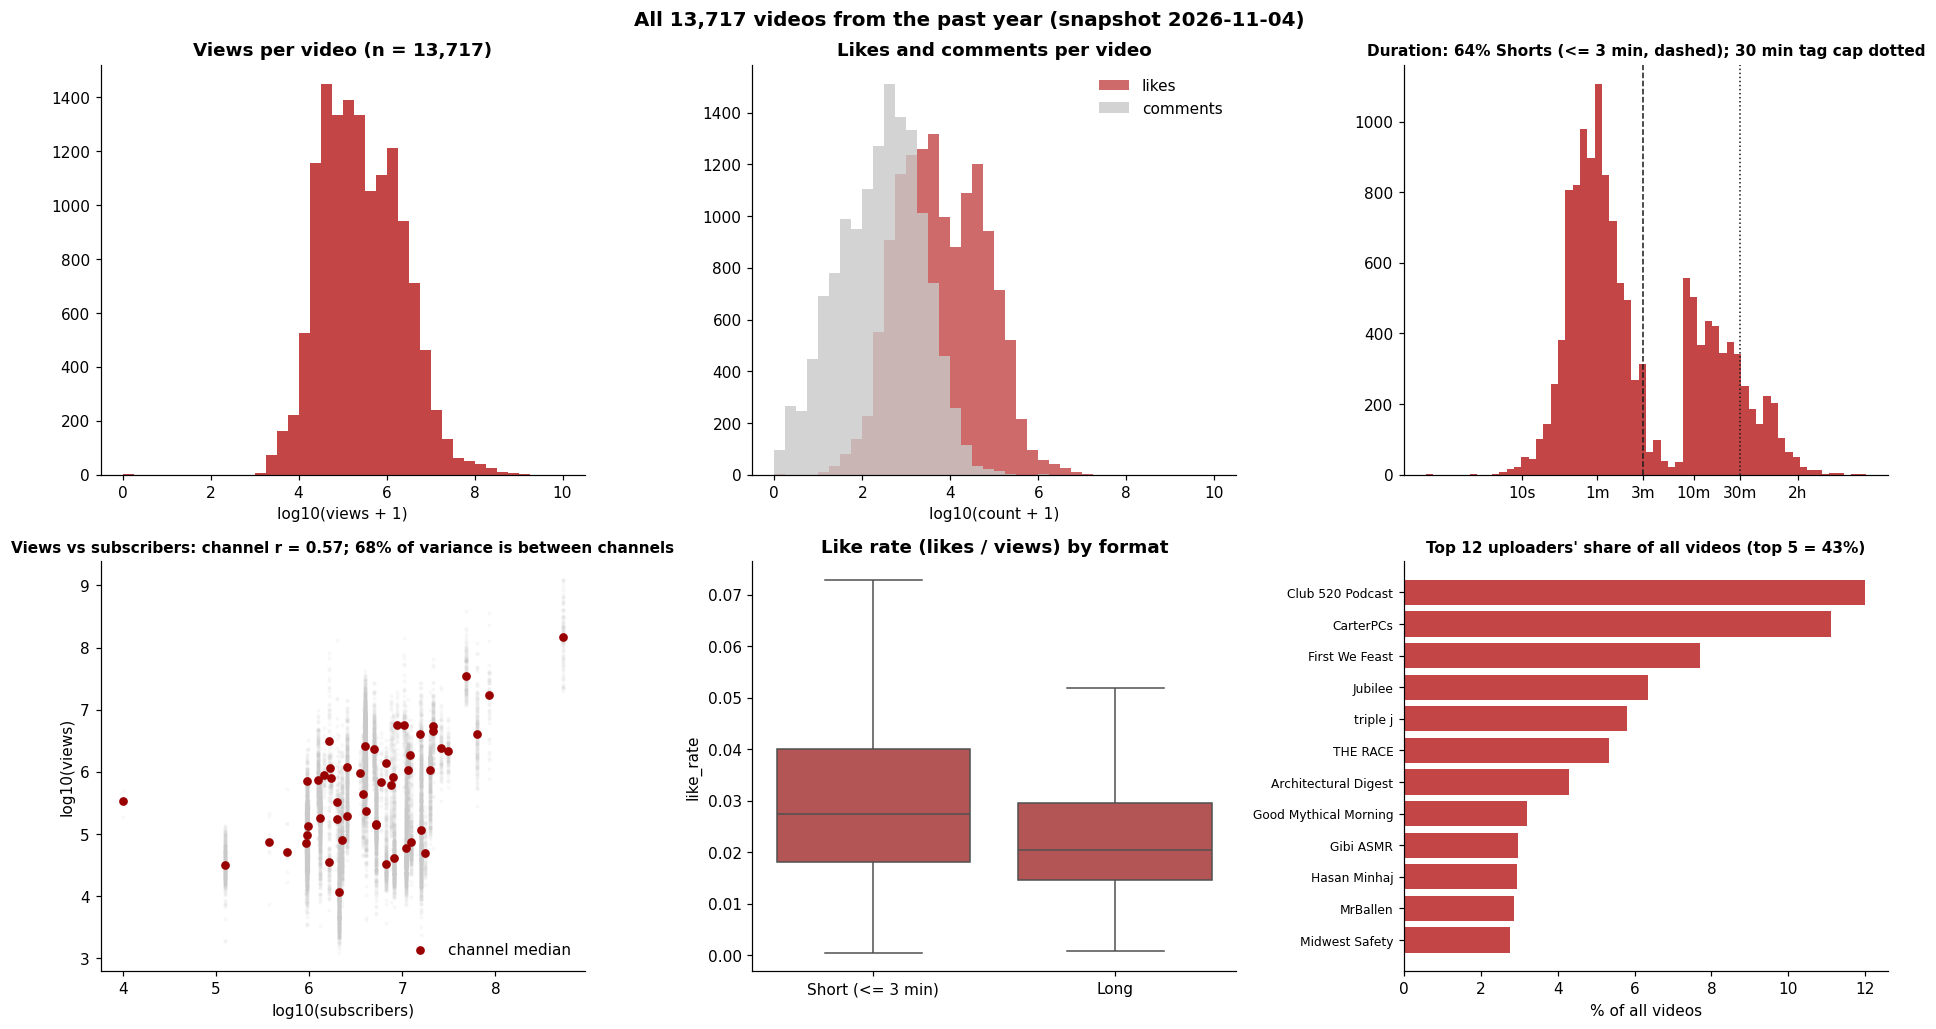

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
bins_log = np.arange(0, 10.01, 0.25)
axes[0, 0].hist(np.log10(df_videos["views"] + 1), bins=bins_log, color=ACCENT)
axes[0, 0].set_title(f"Views per video (n = {len(df_videos):,})", fontweight="bold")
axes[0, 0].set_xlabel("log10(views + 1)")

axes[0, 1].hist(np.log10(df_videos["likes"].dropna() + 1), bins=bins_log, color=ACCENT, alpha=0.8, label="likes")
axes[0, 1].hist(np.log10(df_videos["comments"].dropna() + 1), bins=bins_log, color=GRAY, alpha=0.8, label="comments")
axes[0, 1].set_title("Likes and comments per video", fontweight="bold")
axes[0, 1].set_xlabel("log10(count + 1)")
axes[0, 1].legend(frameon=False)

axes[0, 2].hist(np.log10(df_videos["duration_seconds"].clip(lower=1)), bins=60, color=ACCENT)
axes[0, 2].axvline(np.log10(SHORTS_MAX_SECONDS), color=INK, ls="--", lw=1)
axes[0, 2].axvline(np.log10(1800), color=INK, ls=":", lw=1)
axes[0, 2].set_xticks(np.log10([10, 60, 180, 600, 1800, 7200]), ["10s", "1m", "3m", "10m", "30m", "2h"])
axes[0, 2].set_title(f"Duration: {df_videos['is_short'].mean():.0%} Shorts (<= 3 min, dashed); 30 min tag cap dotted",
                     fontweight="bold", fontsize=10)

df_channel_scatter = df_creators.dropna(subset=["median_views"])
axes[1, 0].scatter(np.log10(df_positive["subs"]), np.log10(df_positive["views"]), s=3, alpha=0.08, color=GRAY)
axes[1, 0].scatter(np.log10(df_channel_scatter["subs"]), np.log10(df_channel_scatter["median_views"]), s=22, color=RED, label="channel median")
axes[1, 0].set_xlabel("log10(subscribers)")
axes[1, 0].set_ylabel("log10(views)")
axes[1, 0].set_title(f"Views vs subscribers: channel r = {channel_r:.2f}; {share_between:.0%} of variance is between channels",
                     fontweight="bold", fontsize=10)
axes[1, 0].legend(frameon=False, loc="lower right")

df_rates = df_videos.dropna(subset=["like_rate"]).assign(format=lambda df: np.where(df["is_short"], "Short (<= 3 min)", "Long"))
sns.boxplot(data=df_rates, x="format", y="like_rate", ax=axes[1, 1], color=ACCENT, showfliers=False)
axes[1, 1].set_title("Like rate (likes / views) by format", fontweight="bold")
axes[1, 1].set_xlabel("")

df_top_uploaders = df_concentration.sort_values("uploads_past_year", ascending=False).head(12)
axes[1, 2].barh(np.arange(len(df_top_uploaders))[::-1], df_top_uploaders["video_share"] * 100, color=ACCENT)
axes[1, 2].set_yticks(np.arange(len(df_top_uploaders))[::-1], df_top_uploaders["channel_title"], fontsize=8)
axes[1, 2].set_title(f"Top 12 uploaders' share of all videos (top 5 = {df_concentration['video_share'].head(5).sum():.0%})",
                     fontweight="bold", fontsize=10)
axes[1, 2].set_xlabel("% of all videos")
fig.suptitle(f"All {len(df_videos):,} videos from the past year (snapshot {SNAPSHOT_DATE})", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_videos.png")
plt.show()

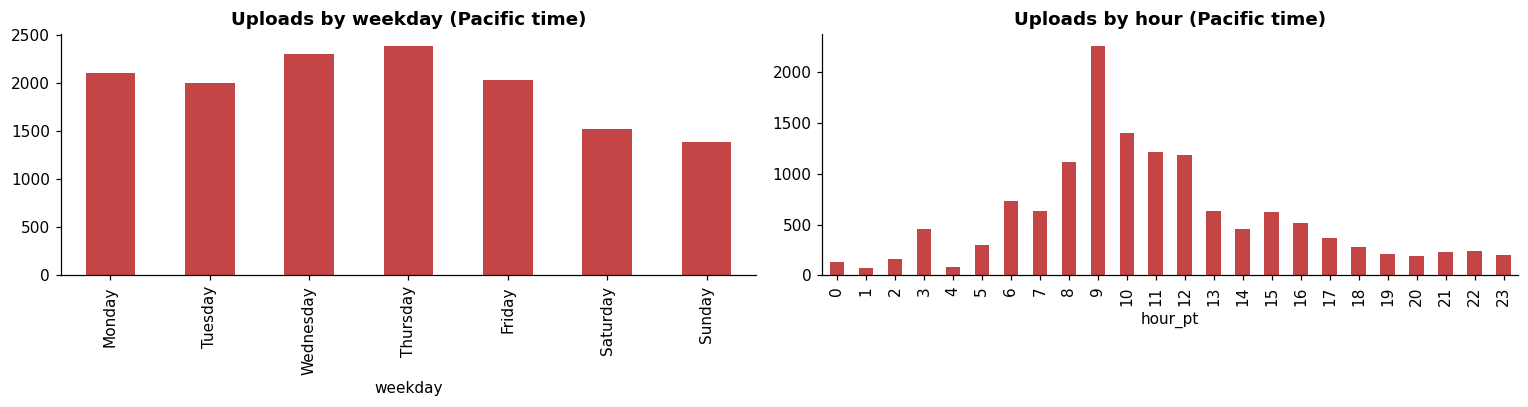

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_videos["weekday"].value_counts().reindex(weekday_order).plot.bar(ax=axes[0], color=ACCENT)
axes[0].set_title("Uploads by weekday (Pacific time)", fontweight="bold")
df_videos["hour_pt"].value_counts().sort_index().plot.bar(ax=axes[1], color=ACCENT)
axes[1].set_title("Uploads by hour (Pacific time)", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Tagged subset vs all videos

In [16]:
"""Tagging rule: each channel's 50 newest videos of <= 30 min (as of the first tagging run), plus every
new upload tagged nightly since 2026-10-22."""
df_untagged = df_videos[~df_videos["is_tagged"]]
df_tagged_videos = df_videos[df_videos["is_tagged"]]
df_eligible = df_videos[df_videos["duration_seconds"] <= 1800]


def describe_sample(df_sample):
    """One column of the comparison table."""
    return pd.Series({
        "videos": len(df_sample),
        "channels": df_sample["channel_id"].nunique(),
        "shorts share": df_sample["is_short"].mean(),
        "median duration (s)": df_sample["duration_seconds"].median(),
        "share > 30 min": (df_sample["duration_seconds"] > 1800).mean(),
        "median age (days)": df_sample["age_days"].median(),
        "share age < 30 days": (df_sample["age_days"] < 30).mean(),
        "median views": df_sample["views"].median(),
        "median global views pct": df_sample["views_pct_global"].median(),
        "median within-channel views pct": df_sample["views_pct_in_channel"].median(),
        "median like rate": df_sample["like_rate"].median(),
        "top-5-channel share": df_sample["channel_id"].value_counts(normalize=True).head(5).sum(),
    })


pd.DataFrame({"all videos": describe_sample(df_videos), "eligible (<= 30 min)": describe_sample(df_eligible),
              "tagged": describe_sample(df_tagged_videos), "not tagged": describe_sample(df_untagged)}).round(3)

,all videos,eligible (<= 30 min),tagged,not tagged
videos,13717.000,12385.000,2788.000,10929.000
channels,52.000,51.000,51.000,48.000
shorts share,0.641,0.710,0.676,0.633
median duration (s),87.000,74.000,79.000,88.000
share > 30 min,0.097,0.000,0.000,0.122
median age (days),189.958,189.722,47.167,219.597
share age < 30 days,0.078,0.078,0.349,0.010
median views,221991.000,205116.000,393886.000,199644.000
median global views pct,0.500,0.488,0.588,0.483
median within-channel views pct,0.502,0.475,0.475,0.511


In [17]:
df_genre_compare = pd.DataFrame({"all": df_videos["genre"].value_counts(normalize=True),
                                 "tagged": df_tagged_videos["genre"].value_counts(normalize=True)}).fillna(0)
df_genre_compare["tagged minus all (pp)"] = 100 * (df_genre_compare["tagged"] - df_genre_compare["all"])
df_genre_compare.sort_values("all", ascending=False).round(3)

,all,tagged,tagged minus all (pp)
genre,,,
Entertainment,0.379,0.311,-6.833
People & Blogs,0.191,0.172,-1.847
Sports,0.167,0.099,-6.752
Education,0.089,0.168,7.805
Science & Technology,0.056,0.087,3.153
Comedy,0.053,0.048,-0.551
News & Politics,0.031,0.034,0.374
Gaming,0.012,0.005,-0.693
Howto & Style,0.010,0.033,2.294


In [18]:
"""Per channel: share of its past-year videos that are tagged, and its share of the tagged set vs all videos."""
df_channel_mix = df_creators[df_creators["uploads_past_year"] > 0][["channel_title", "uploads_past_year", "tagged_videos", "shorts_share"]].copy()
df_channel_mix["share_tagged"] = df_channel_mix["tagged_videos"] / df_channel_mix["uploads_past_year"]
df_channel_mix["share_of_all"] = df_channel_mix["uploads_past_year"] / df_channel_mix["uploads_past_year"].sum()
df_channel_mix["share_of_tagged"] = df_channel_mix["tagged_videos"] / df_channel_mix["tagged_videos"].sum()
print(f"channels fully tagged (100%): {(df_channel_mix['share_tagged'] >= 0.999).sum()}; under 10% tagged: {(df_channel_mix['share_tagged'] < 0.10).sum()}")
print(f"tagged videos per channel: median {df_channel_mix['tagged_videos'].median():.0f}, min {df_channel_mix['tagged_videos'].min()}, max {df_channel_mix['tagged_videos'].max()}")
print(f"channels with < 20 tagged videos: {(df_channel_mix['tagged_videos'] < 20).sum()}")
df_channel_mix.sort_values("share_of_all", ascending=False).round(3)

channels fully tagged (100%): 4; under 10% tagged: 5
tagged videos per channel: median 56, min 0, max 142
channels with < 20 tagged videos: 9


,channel_title,uploads_past_year,tagged_videos,shorts_share,share_tagged,share_of_all,share_of_tagged
46,Club 520 Podcast,1645,117,0.272,0.071,0.120,0.042
28,CarterPCs,1523,142,1.000,0.093,0.111,0.051
10,First We Feast,1057,120,0.861,0.114,0.077,0.043
15,Jubilee,871,103,0.853,0.118,0.063,0.037
34,triple j,796,90,0.634,0.113,0.058,0.032
42,THE RACE,730,90,0.615,0.123,0.053,0.032
18,Architectural Digest,588,61,0.847,0.104,0.043,0.022
8,Good Mythical Morning,438,79,0.400,0.180,0.032,0.028
24,Gibi ASMR,407,73,0.857,0.179,0.030,0.026
33,Hasan Minhaj,403,63,0.859,0.156,0.029,0.023


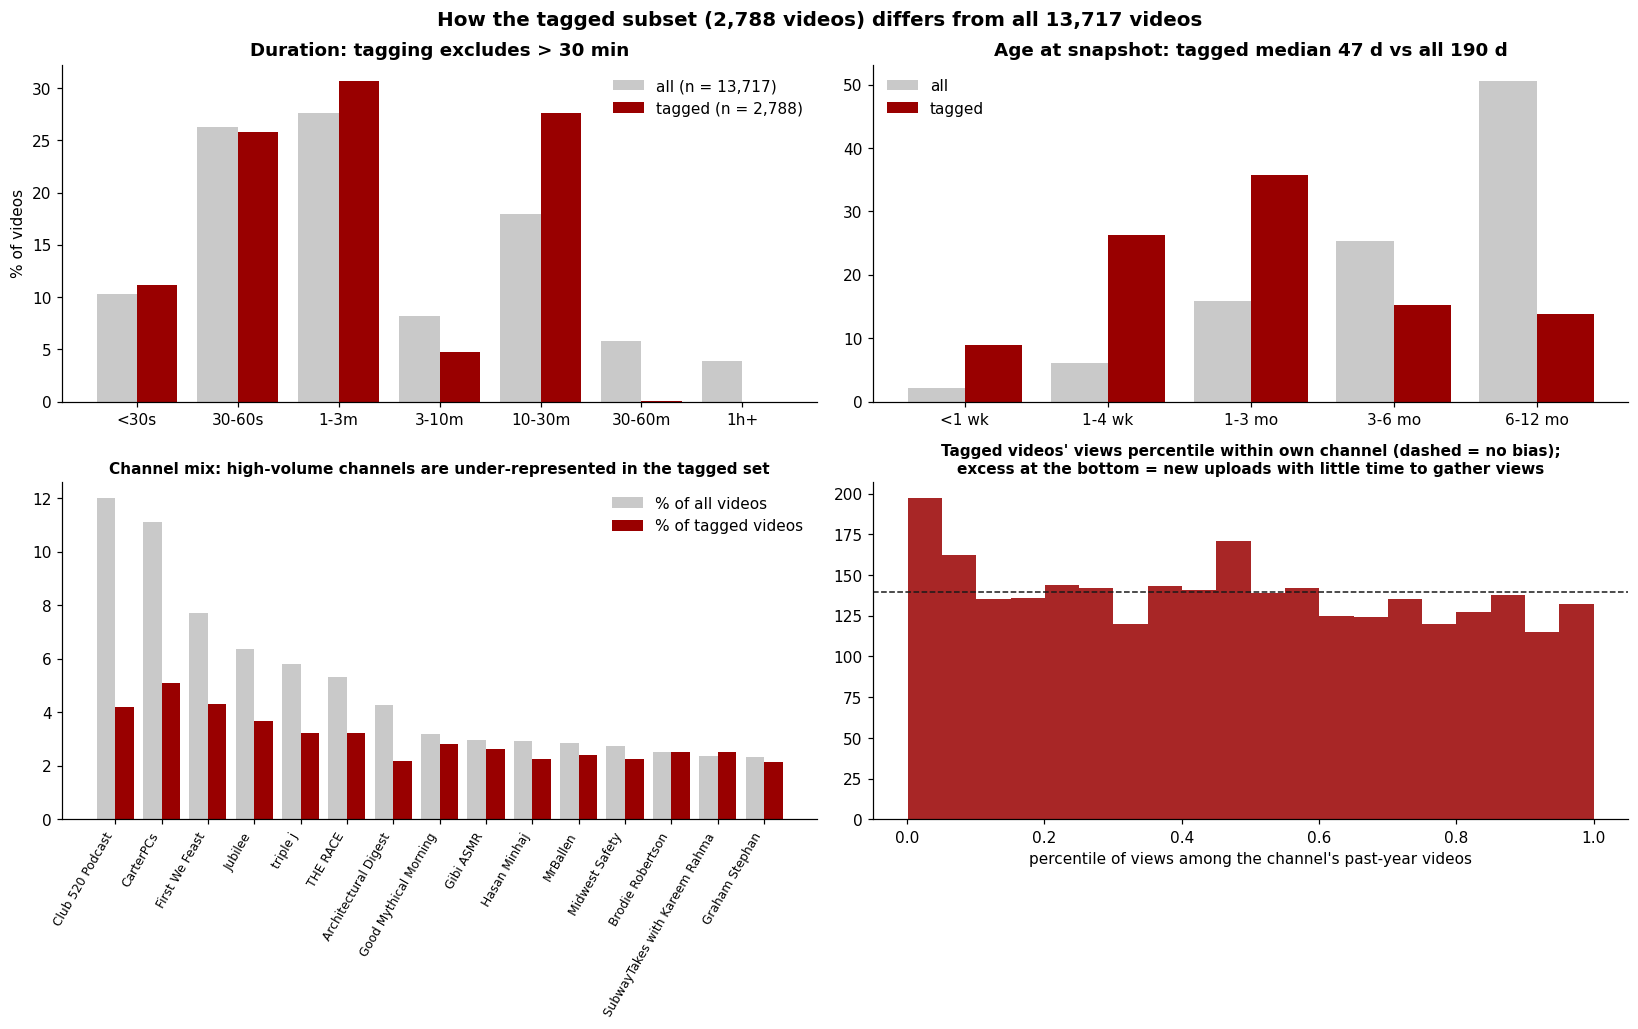

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
duration_bins = np.log10([1, 30, 60, 180, 600, 1800, 3600, 20000])
duration_labels = ["<30s", "30-60s", "1-3m", "3-10m", "10-30m", "30-60m", "1h+"]
all_duration = pd.cut(np.log10(df_videos["duration_seconds"].clip(lower=1)), duration_bins, labels=duration_labels, include_lowest=True).value_counts(normalize=True, sort=False)
tagged_duration = pd.cut(np.log10(df_tagged_videos["duration_seconds"].clip(lower=1)), duration_bins, labels=duration_labels, include_lowest=True).value_counts(normalize=True, sort=False)
width = 0.4
axes[0, 0].bar(np.arange(len(duration_labels)) - width / 2, all_duration * 100, width, color=GRAY, label=f"all (n = {len(df_videos):,})")
axes[0, 0].bar(np.arange(len(duration_labels)) + width / 2, tagged_duration * 100, width, color=RED, label=f"tagged (n = {len(df_tagged_videos):,})")
axes[0, 0].set_xticks(np.arange(len(duration_labels)), duration_labels)
axes[0, 0].set_title("Duration: tagging excludes > 30 min", fontweight="bold")
axes[0, 0].set_ylabel("% of videos")
axes[0, 0].legend(frameon=False)

age_bins = [0, 7, 30, 90, 180, 366]
age_labels = ["<1 wk", "1-4 wk", "1-3 mo", "3-6 mo", "6-12 mo"]
all_age = pd.cut(df_videos["age_days"], age_bins, labels=age_labels, right=False).value_counts(normalize=True, sort=False)
tagged_age = pd.cut(df_tagged_videos["age_days"], age_bins, labels=age_labels, right=False).value_counts(normalize=True, sort=False)
axes[0, 1].bar(np.arange(len(age_labels)) - width / 2, all_age * 100, width, color=GRAY, label="all")
axes[0, 1].bar(np.arange(len(age_labels)) + width / 2, tagged_age * 100, width, color=RED, label="tagged")
axes[0, 1].set_xticks(np.arange(len(age_labels)), age_labels)
axes[0, 1].set_title(f"Age at snapshot: tagged median {df_tagged_videos['age_days'].median():.0f} d vs all {df_videos['age_days'].median():.0f} d",
                     fontweight="bold")
axes[0, 1].legend(frameon=False)

df_mix_plot = df_channel_mix.sort_values("share_of_all", ascending=False).head(15)
axes[1, 0].bar(np.arange(len(df_mix_plot)) - width / 2, df_mix_plot["share_of_all"] * 100, width, color=GRAY, label="% of all videos")
axes[1, 0].bar(np.arange(len(df_mix_plot)) + width / 2, df_mix_plot["share_of_tagged"] * 100, width, color=RED, label="% of tagged videos")
axes[1, 0].set_xticks(np.arange(len(df_mix_plot)), df_mix_plot["channel_title"], rotation=60, ha="right", fontsize=8)
axes[1, 0].set_title("Channel mix: high-volume channels are under-represented in the tagged set", fontweight="bold", fontsize=10)
axes[1, 0].legend(frameon=False)

axes[1, 1].hist(df_tagged_videos["views_pct_in_channel"], bins=20, color=RED, alpha=0.85)
axes[1, 1].axhline(len(df_tagged_videos) / 20, color=INK, ls="--", lw=1)
axes[1, 1].set_title("Tagged videos' views percentile within own channel (dashed = no bias);\nexcess at the bottom = new uploads with little time to gather views",
                     fontweight="bold", fontsize=10)
axes[1, 1].set_xlabel("percentile of views among the channel's past-year videos")
fig.suptitle(f"How the tagged subset ({len(df_tagged_videos):,} videos) differs from all {len(df_videos):,} videos",
             fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_tagged_vs_all.png")
plt.show()

## 4. Traits

In [20]:
df_traits = df_tags[["id"] + trait_columns].merge(
    df_videos[["id", "channel_id", "channel_title", "genre", "log_views", "is_short", "age_days", "duration_seconds"]], on="id")
print(f"tagged videos analysed: {len(df_traits):,} from {df_traits['channel_id'].nunique()} channels")

prevalence_rows = []
for column in trait_columns:
    level_counts = df_traits[column].value_counts().reindex(range(5), fill_value=0)
    nonzero_levels = level_counts[1:] if trait_scale[column] == "linear" else level_counts[1:2]
    prevalence_rows.append({
        "trait": column, "category": trait_category[column], "scale": trait_scale[column],
        "present_share": (df_traits[column] >= 1).mean(), "mean_score": df_traits[column].mean(),
        "n_0": level_counts[0], "n_1": level_counts[1], "n_2": level_counts[2], "n_3": level_counts[3], "n_4": level_counts[4],
        "sparse_levels": int((nonzero_levels < SPARSE_LEVEL_MIN_VIDEOS).sum()),
        "channels_present": df_traits.loc[df_traits[column] >= 1, "channel_id"].nunique(),
        "top_channel_share_of_present": df_traits.loc[df_traits[column] >= 1, "channel_id"].value_counts(normalize=True).max(),
    })
df_prevalence = pd.DataFrame(prevalence_rows)
df_prevalence["near_constant"] = np.where(df_prevalence["present_share"] > NEAR_CONSTANT_HIGH, "almost always",
                                          np.where(df_prevalence["present_share"] < NEAR_CONSTANT_LOW, "almost never", ""))
df_prevalence.sort_values("present_share", ascending=False).round(3)

tagged videos analysed: 2,788 from 51 channels


,trait,category,scale,present_share,mean_score,n_0,n_1,n_2,n_3,n_4,sparse_levels,channels_present,top_channel_share_of_present,near_constant
49,editing_pace,Production,linear,1.000,2.761,0,139,863,1310,476,0,51,0.051,almost always
44,production,Production,linear,1.000,3.004,0,24,666,1373,725,0,51,0.051,almost always
50,music_sound_design,Production,linear,0.989,2.122,31,476,1568,549,164,0,51,0.052,almost always
51,on_screen_text_captions,Production,linear,0.976,2.901,66,121,355,1727,519,0,51,0.052,almost always
59,curiosity_gap_hook,Audience Hooks,linear,0.962,2.467,107,170,1112,1112,287,0,51,0.053,almost always
46,visual_dependency,Production,linear,0.961,2.499,108,311,793,1234,342,0,51,0.053,almost always
48,face_on_camera,Production,linear,0.937,3.376,175,23,259,454,1877,0,51,0.054,almost always
61,direct_address,Audience Hooks,linear,0.841,2.437,442,229,354,1194,569,0,51,0.061,
36,high_energy,Tone and Emotion,linear,0.829,1.733,477,421,1347,456,87,0,51,0.061,
52,scripted,Production,linear,0.811,2.210,526,339,714,441,768,0,51,0.062,


In [21]:
linear_levels = df_prevalence[df_prevalence["scale"] == "linear"][["n_1", "n_2", "n_3", "n_4"]]
print(f"non-zero levels of linear traits: {linear_levels.size}; with < {SPARSE_LEVEL_MIN_VIDEOS} videos: {(linear_levels < SPARSE_LEVEL_MIN_VIDEOS).sum().sum()}"
      f" ({(linear_levels < SPARSE_LEVEL_MIN_VIDEOS).sum().sum() / linear_levels.size:.0%}); with 0 videos: {(linear_levels == 0).sum().sum()}")
print(f"level 4 used fewer than {SPARSE_LEVEL_MIN_VIDEOS} times: {(linear_levels['n_4'] < SPARSE_LEVEL_MIN_VIDEOS).sum()} of {len(linear_levels)} linear traits")
print(f"traits present in > {NEAR_CONSTANT_HIGH:.0%}: {df_prevalence.loc[df_prevalence['near_constant'] == 'almost always', 'trait'].tolist()}")
print(f"traits present in < {NEAR_CONSTANT_LOW:.0%}: {(df_prevalence['near_constant'] == 'almost never').sum()} -> "
      f"{df_prevalence.loc[df_prevalence['near_constant'] == 'almost never', 'trait'].tolist()}")
print(f"traits where one channel supplies > 50% of the present videos: "
      f"{df_prevalence.loc[df_prevalence['top_channel_share_of_present'] > 0.5, 'trait'].tolist()}")
print(f"\nmedian traits present per video: {(df_traits[trait_columns] >= 1).sum(axis=1).median():.0f} of {len(trait_columns)}")
print("\nscore distribution by category (share of all trait x video cells at each level):")
df_long = df_traits[trait_columns].melt(var_name="trait", value_name="score")
df_long["category"] = df_long["trait"].map(trait_category)
pd.crosstab(df_long["category"], df_long["score"], normalize="index").round(3)

non-zero levels of linear traits: 300; with < 20 videos: 31 (10%); with 0 videos: 1
level 4 used fewer than 20 times: 10 of 75 linear traits
traits present in > 90%: ['production', 'visual_dependency', 'face_on_camera', 'editing_pace', 'music_sound_design', 'on_screen_text_captions', 'curiosity_gap_hook']
traits present in < 5%: 8 -> ['prank', 'gameplay', 'music_performance', 'asmr_ambient', 'haul_shopping', 'giveaway_generosity', 'seasonal_holiday_tie_in', 'beauty_fashion']
traits where one channel supplies > 50% of the present videos: ['music_performance', 'asmr_ambient']

median traits present per video: 26 of 79

score distribution by category (share of all trait x video cells at each level):


score,0,1,2,3,4
category,,,,,
Audience Hooks,0.549,0.203,0.088,0.117,0.043
Format,0.791,0.056,0.052,0.065,0.035
Production,0.199,0.117,0.218,0.269,0.197
Subject Matter,0.824,0.060,0.040,0.023,0.053
Tone and Emotion,0.615,0.155,0.144,0.071,0.016


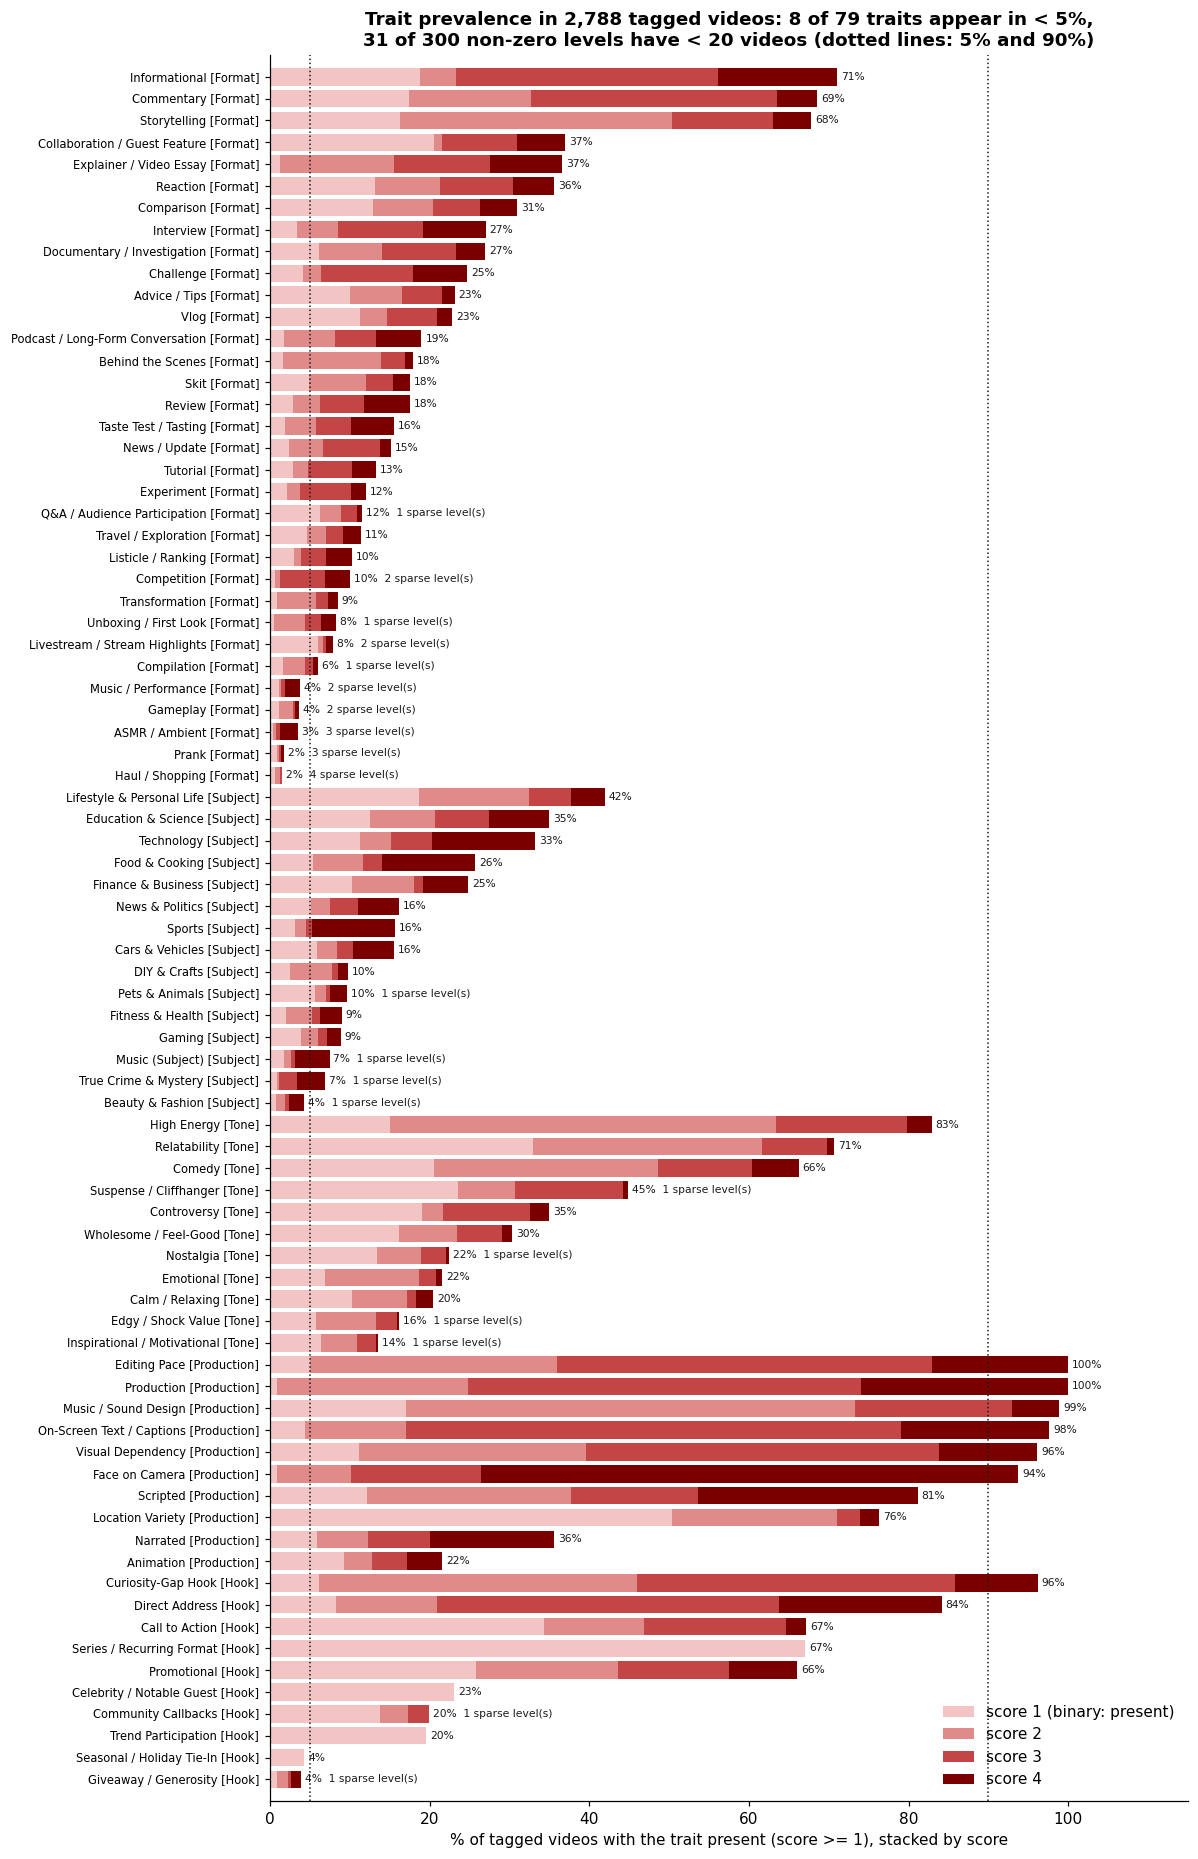

In [22]:
category_order = ["Format", "Subject Matter", "Tone and Emotion", "Production", "Audience Hooks"]
df_prev_plot = df_prevalence.copy()
df_prev_plot["category"] = pd.Categorical(df_prev_plot["category"], category_order, ordered=True)
df_prev_plot = df_prev_plot.sort_values(["category", "present_share"], ascending=[False, True]).reset_index(drop=True)
level_colors = ["#F2C4C4", "#E08A8A", "#C44545", "#7A0000"]
positions = np.arange(len(df_prev_plot))
total = len(df_traits)

fig, ax = plt.subplots(figsize=(11, 17))
left = np.zeros(len(df_prev_plot))
for level, color in zip([1, 2, 3, 4], level_colors):
    shares = df_prev_plot[f"n_{level}"] / total * 100
    ax.barh(positions, shares, left=left, color=color, label=f"score {level}" if level > 1 else "score 1 (binary: present)")
    left = left + shares
for position, row in df_prev_plot.iterrows():
    marker = ""
    if row["sparse_levels"] > 0:
        marker = f"  {row['sparse_levels']} sparse level(s)"
    ax.text(row["present_share"] * 100 + 0.5, position, f"{row['present_share']:.0%}{marker}", va="center", fontsize=7, color=INK)
category_short = {"Format": "Format", "Subject Matter": "Subject", "Tone and Emotion": "Tone", "Production": "Production", "Audience Hooks": "Hook"}
labels = [f"{trait_name[trait]} [{category_short[category]}]" for trait, category in zip(df_prev_plot["trait"], df_prev_plot["category"])]
ax.set_yticks(positions, labels, fontsize=7.5)
ax.axvline(NEAR_CONSTANT_LOW * 100, color=INK, ls=":", lw=1)
ax.axvline(NEAR_CONSTANT_HIGH * 100, color=INK, ls=":", lw=1)
ax.set_xlim(0, 115)
ax.set_xlabel("% of tagged videos with the trait present (score >= 1), stacked by score")
ax.set_ylim(-1, len(df_prev_plot))
ax.legend(frameon=False, loc="lower right")
sparse_total = (linear_levels < SPARSE_LEVEL_MIN_VIDEOS).sum().sum()
ax.set_title(f"Trait prevalence in {total:,} tagged videos: {(df_prevalence['near_constant'] == 'almost never').sum()} of {len(trait_columns)} traits appear in < 5%,\n"
             f"{sparse_total} of {linear_levels.size} non-zero levels have < {SPARSE_LEVEL_MIN_VIDEOS} videos (dotted lines: 5% and 90%)",
             fontweight="bold", fontsize=12)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_trait_prevalence.png")
plt.show()

In [23]:
"""Spearman correlation between trait scores. Traits with no variation are dropped first."""
varying_traits = [column for column in trait_columns if df_traits[column].nunique() > 1]
df_spearman = df_traits[varying_traits].corr(method="spearman")
pair_rows = []
for first_index, first_trait in enumerate(varying_traits):
    for second_trait in varying_traits[first_index + 1:]:
        pair_rows.append({"trait_a": first_trait, "trait_b": second_trait, "rho": df_spearman.loc[first_trait, second_trait]})
df_pairs = pd.DataFrame(pair_rows)
df_pairs["abs_rho"] = df_pairs["rho"].abs()
df_top_pairs = df_pairs.sort_values("abs_rho", ascending=False).head(15).reset_index(drop=True)
print(f"pairs: {len(df_pairs):,}; |rho| >= 0.5: {(df_pairs['abs_rho'] >= 0.5).sum()}; >= 0.7: {(df_pairs['abs_rho'] >= 0.7).sum()}")
df_top_pairs.round(3)

pairs: 3,081; |rho| >= 0.5: 33; >= 0.7: 4


,trait_a,trait_b,rho,abs_rho
0,taste_test_tasting,food_cooking,0.769,0.769
1,informational,explainer_video_essay,0.743,0.743
2,narrated,face_on_camera,-0.703,0.703
3,high_energy,editing_pace,0.700,0.700
4,explainer_video_essay,education_science,0.697,0.697
5,promotional,call_to_action,0.664,0.664
6,informational,education_science,0.643,0.643
7,suspense_cliffhanger,curiosity_gap_hook,0.626,0.626
8,documentary_investigation,explainer_video_essay,0.610,0.610
9,narrated,scripted,0.602,0.602


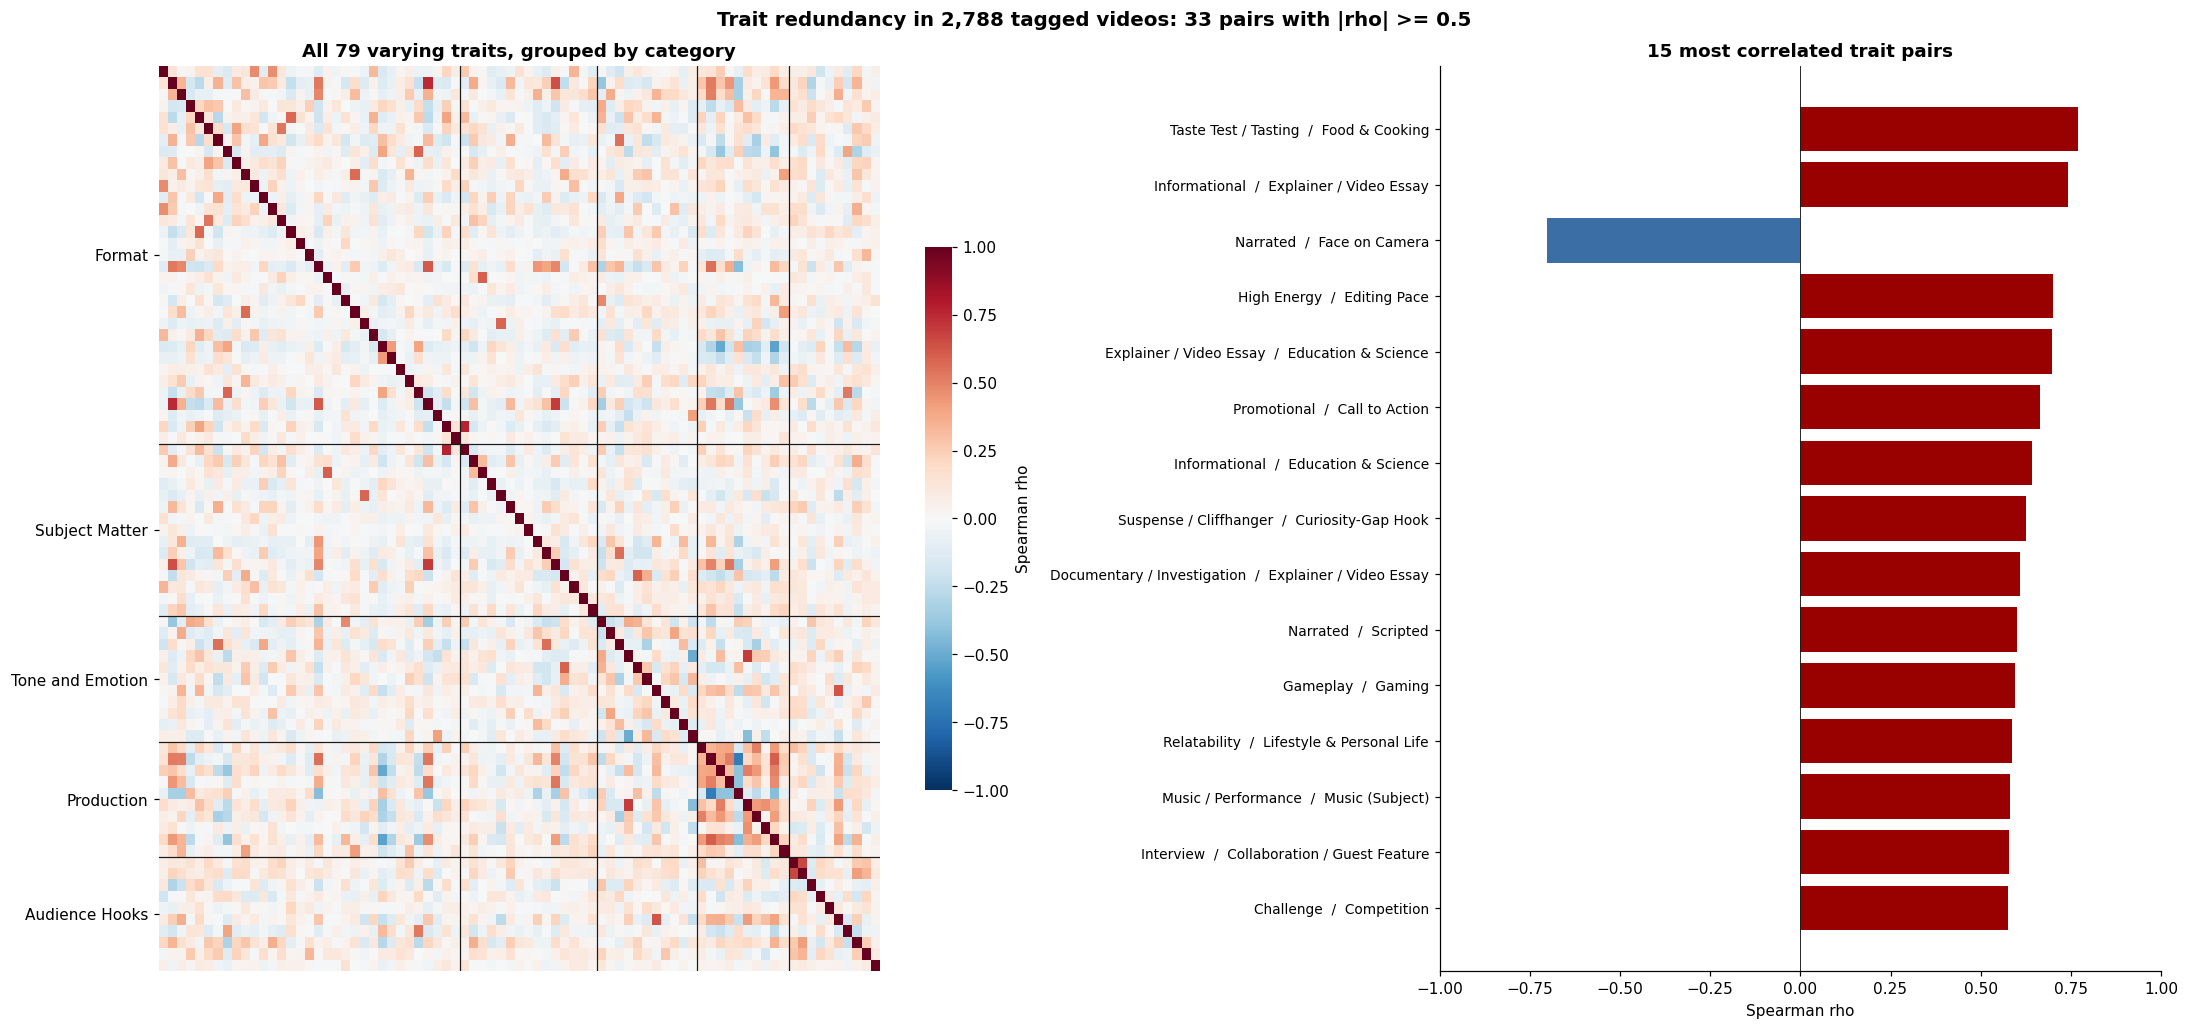

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9.5), gridspec_kw={"width_ratios": [1.25, 1]})
ordered_traits = [column for category in category_order for column in varying_traits if trait_category[column] == category]
sns.heatmap(df_spearman.loc[ordered_traits, ordered_traits], cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0],
            xticklabels=False, yticklabels=False, cbar_kws={"label": "Spearman rho", "shrink": 0.6})
boundaries = np.cumsum([sum(trait_category[column] == category for column in ordered_traits) for category in category_order])
for boundary in boundaries[:-1]:
    axes[0].axhline(boundary, color=INK, lw=0.8)
    axes[0].axvline(boundary, color=INK, lw=0.8)
tick_positions = [boundary - count / 2 for boundary, count in zip(boundaries, np.diff(np.concatenate([[0], boundaries])))]
axes[0].set_yticks(tick_positions, category_order, rotation=0)
axes[0].set_title(f"All {len(ordered_traits)} varying traits, grouped by category", fontweight="bold")

pair_labels = [f"{trait_name[row['trait_a']]}  /  {trait_name[row['trait_b']]}" for _, row in df_top_pairs.iterrows()]
axes[1].barh(np.arange(len(df_top_pairs))[::-1], df_top_pairs["rho"], color=[RED if rho > 0 else BLUE for rho in df_top_pairs["rho"]])
axes[1].set_yticks(np.arange(len(df_top_pairs))[::-1], pair_labels, fontsize=9)
axes[1].axvline(0, color=INK, lw=0.6)
axes[1].set_xlim(-1, 1)
axes[1].set_xlabel("Spearman rho")
axes[1].set_title("15 most correlated trait pairs", fontweight="bold")
fig.suptitle(f"Trait redundancy in {len(df_traits):,} tagged videos: {(df_pairs['abs_rho'] >= 0.5).sum()} pairs with |rho| >= 0.5",
             fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_trait_correlations.png")
plt.show()

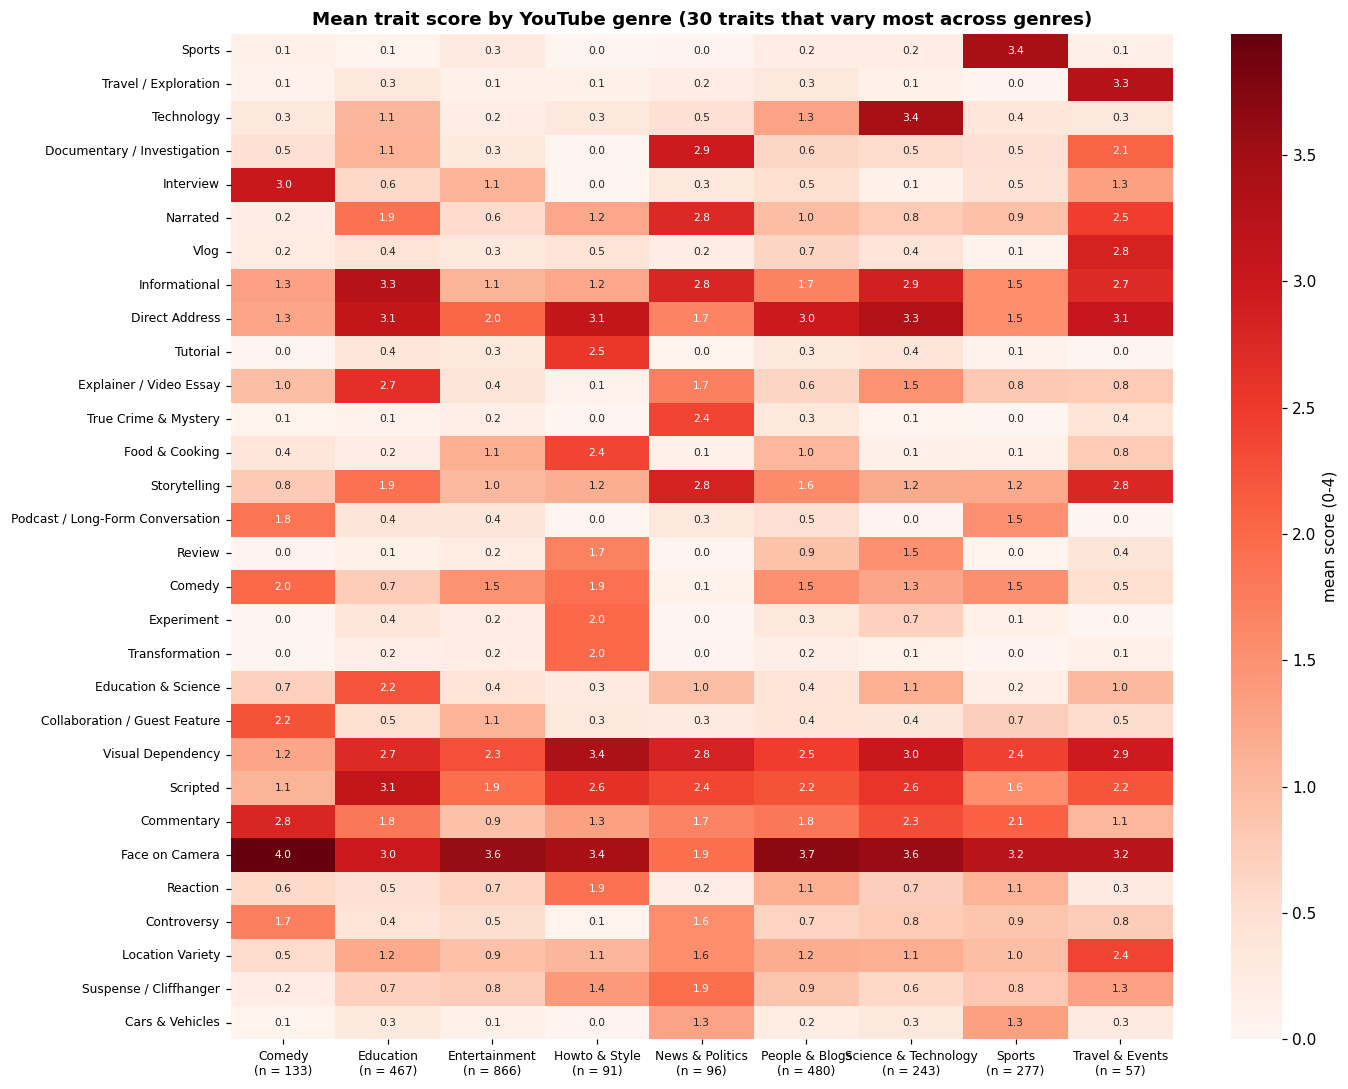

tagged videos per genre: {'Entertainment': 866, 'People & Blogs': 480, 'Education': 467, 'Sports': 277, 'Science & Technology': 243, 'Comedy': 133, 'News & Politics': 96, 'Howto & Style': 91, 'Travel & Events': 57, 'Pets & Animals': 36, 'Autos & Vehicles': 29, 'Gaming': 13}


In [25]:
"""Mean trait score by the video's YouTube genre (genres with >= 50 tagged videos), for the 30 traits
whose mean varies most across genres."""
genre_counts = df_traits["genre"].value_counts()
kept_genres = genre_counts[genre_counts >= 50].index.tolist()
df_genre_means = df_traits[df_traits["genre"].isin(kept_genres)].groupby("genre")[trait_columns].mean()
top_spread_traits = df_genre_means.std().sort_values(ascending=False).head(30).index.tolist()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(df_genre_means[top_spread_traits].T, cmap="Reds", annot=True, fmt=".1f", annot_kws={"fontsize": 7}, ax=ax,
            cbar_kws={"label": "mean score (0-4)"})
ax.set_xticklabels([f"{genre}\n(n = {genre_counts[genre]})" for genre in df_genre_means.index], rotation=0, fontsize=8)
ax.set_yticklabels([trait_name[column] for column in top_spread_traits], fontsize=8)
ax.set_xlabel("")
ax.set_title("Mean trait score by YouTube genre (30 traits that vary most across genres)", fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_trait_by_genre.png")
plt.show()
print("tagged videos per genre:", genre_counts.to_dict())

In [26]:
"""Univariate association of each trait with log10 views. CORRELATIONAL ONLY. 'raw' compares across all
videos and is confounded by channel (channel size explains most of the variance in views);
'within channel' uses log views minus the channel's mean over its tagged videos, which removes channel
level differences but not other confounders."""
df_traits["log_views_within"] = df_traits["log_views"] - df_traits["log_views"].groupby(df_traits["channel_id"]).transform("mean")
log_age_within = np.log10(df_traits["age_days"] + 1) - np.log10(df_traits["age_days"] + 1).groupby(df_traits["channel_id"]).transform("mean")
age_slope = np.polyfit(log_age_within, df_traits["log_views_within"], 1)[0]
df_traits["log_views_within_age"] = df_traits["log_views_within"] - age_slope * log_age_within
print(f"within channel, log10 views rise {age_slope:.2f} per 10x age (tagged videos are young, so age matters)")
association_rows = []
for column in varying_traits:
    association_rows.append({
        "trait": column, "category": trait_category[column], "present_share": (df_traits[column] >= 1).mean(),
        "rho_raw": stats.spearmanr(df_traits[column], df_traits["log_views"]).statistic,
        "rho_within_channel": stats.spearmanr(df_traits[column], df_traits["log_views_within"]).statistic,
        "rho_within_channel_age_adj": stats.spearmanr(df_traits[column], df_traits["log_views_within_age"]).statistic,
    })
df_assoc = pd.DataFrame(association_rows)
df_assoc["sign_flips"] = np.sign(df_assoc["rho_raw"]) != np.sign(df_assoc["rho_within_channel"])
print(f"traits whose sign flips once channel is removed: {df_assoc['sign_flips'].sum()} of {len(df_assoc)}")
print(f"median |rho| raw {df_assoc['rho_raw'].abs().median():.3f}, within channel {df_assoc['rho_within_channel'].abs().median():.3f}, "
      f"within channel + age {df_assoc['rho_within_channel_age_adj'].abs().median():.3f}; max |rho| within channel + age "
      f"{df_assoc['rho_within_channel_age_adj'].abs().max():.3f}")
df_assoc.reindex(df_assoc["rho_within_channel"].abs().sort_values(ascending=False).index).head(15).round(3)

within channel, log10 views rise 0.21 per 10x age (tagged videos are young, so age matters)
traits whose sign flips once channel is removed: 27 of 79
median |rho| raw 0.134, within channel 0.049, within channel + age 0.050; max |rho| within channel + age 0.153


,trait,category,present_share,rho_raw,rho_within_channel,rho_within_channel_age_adj,sign_flips
39,suspense_cliffhanger,Tone and Emotion,0.448,0.349,0.154,0.153,False
59,curiosity_gap_hook,Audience Hooks,0.962,0.375,0.135,0.131,False
8,comparison,Format,0.309,0.159,0.133,0.124,False
55,call_to_action,Audience Hooks,0.672,-0.005,0.129,0.127,True
17,documentary_investigation,Format,0.269,0.081,0.127,0.124,False
62,community_callbacks,Audience Hooks,0.199,-0.001,0.117,0.122,True
57,series_recurring_format,Audience Hooks,0.670,-0.086,0.116,0.115,True
40,nostalgia,Tone and Emotion,0.224,-0.001,0.113,0.118,True
2,storytelling,Format,0.678,0.158,0.113,0.117,False
78,cars_vehicles,Subject Matter,0.155,0.137,0.104,0.105,False


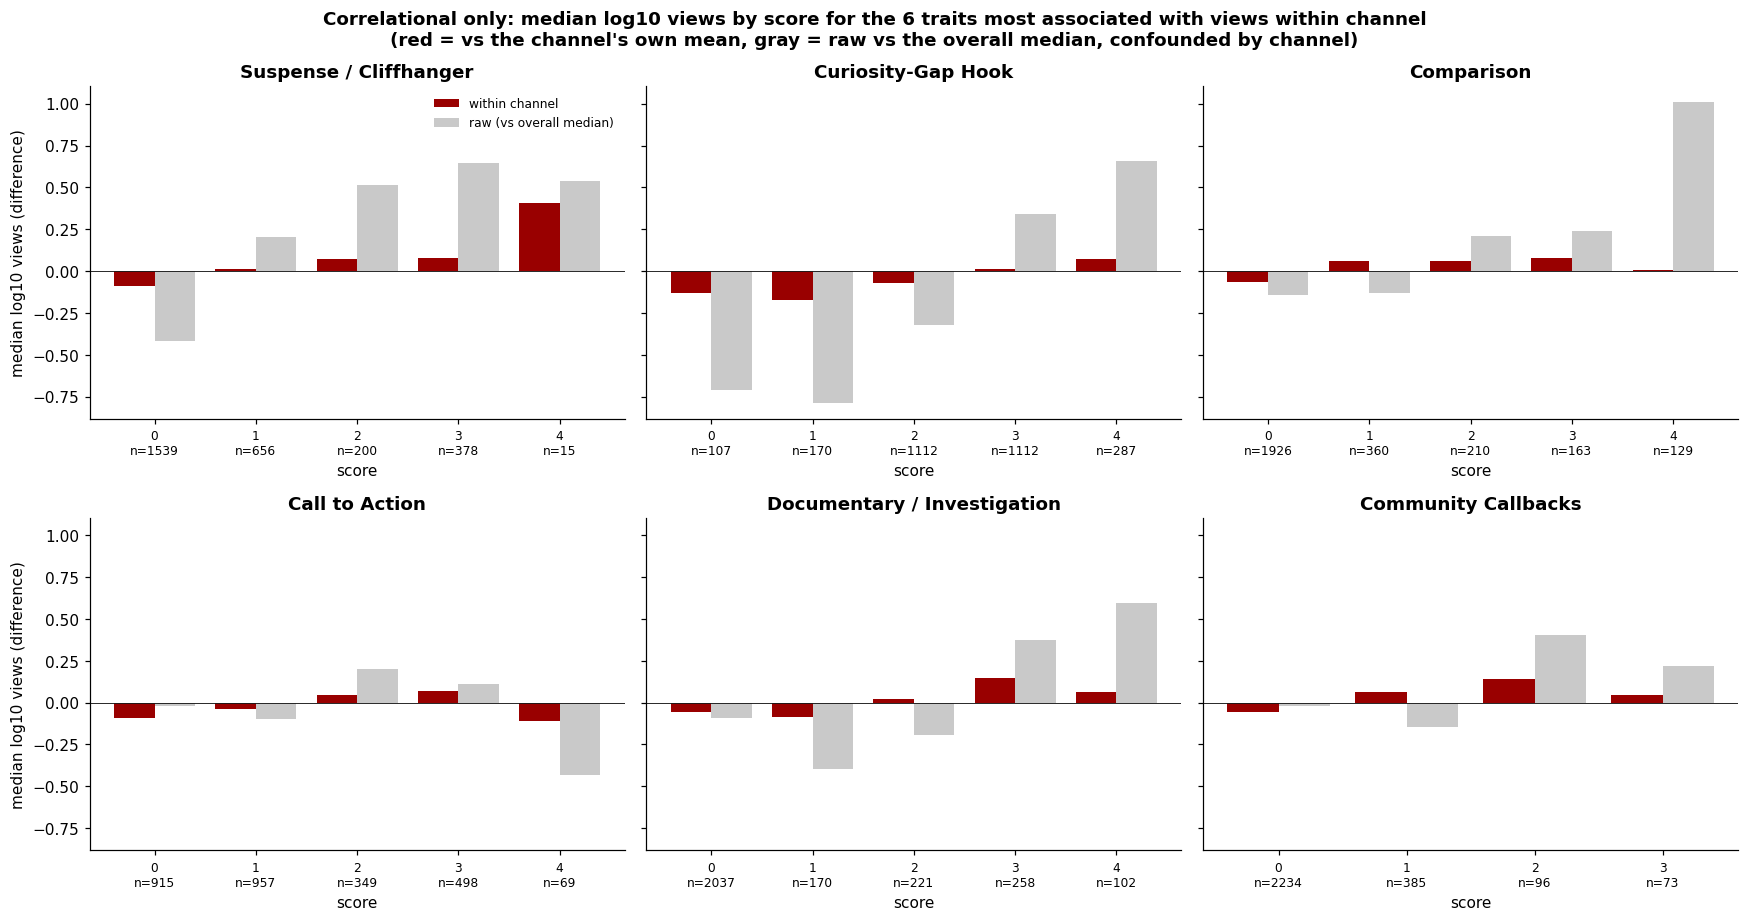

In [27]:
strongest_traits = df_assoc.reindex(df_assoc["rho_within_channel"].abs().sort_values(ascending=False).index)["trait"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
for ax, column in zip(axes.flat, strongest_traits):
    df_level = df_traits.groupby(column).agg(median_within=("log_views_within", "median"), median_raw=("log_views", "median"),
                                             videos=("id", "size")).reset_index()
    ax.bar(df_level[column] - 0.2, df_level["median_within"], 0.4, color=RED, label="within channel")
    ax.bar(df_level[column] + 0.2, df_level["median_raw"] - df_traits["log_views"].median(), 0.4, color=GRAY, label="raw (vs overall median)")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_xticks(df_level[column], [f"{level}\nn={videos}" for level, videos in zip(df_level[column], df_level["videos"])], fontsize=8)
    ax.set_title(trait_name[column], fontweight="bold")
    ax.set_xlabel("score")
axes[0, 0].set_ylabel("median log10 views (difference)")
axes[1, 0].set_ylabel("median log10 views (difference)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Correlational only: median log10 views by score for the 6 traits most associated with views within channel\n"
             "(red = vs the channel's own mean, gray = raw vs the overall median, confounded by channel)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/eda_trait_views.png")
plt.show()

In [28]:
"""Effective sample per trait level: the number of distinct channels behind each non-zero level. A level
seen in many videos from one or two channels cannot be separated from those channels."""
level_channel_rows = []
for column in trait_columns:
    for level in range(1, 5):
        level_mask = df_traits[column] == level
        if level_mask.sum() > 0:
            level_channel_rows.append({"trait": column, "level": level, "videos": int(level_mask.sum()),
                                       "channels": df_traits.loc[level_mask, "channel_id"].nunique()})
df_level_channels = pd.DataFrame(level_channel_rows)
print(f"non-zero trait levels observed: {len(df_level_channels)}; seen in <= 3 channels: {(df_level_channels['channels'] <= 3).sum()}")
print(f"ratio of tagged videos to one-hot columns if every observed level became a dummy: "
      f"{len(df_traits):,} / {len(df_level_channels)} = {len(df_traits) / len(df_level_channels):.1f}")
print(f"distinct channels in the tagged set: {df_traits['channel_id'].nunique()} (the effective n for channel-level effects)")

non-zero trait levels observed: 303; seen in <= 3 channels: 4
ratio of tagged videos to one-hot columns if every observed level became a dummy: 2,788 / 303 = 9.2
distinct channels in the tagged set: 51 (the effective n for channel-level effects)


## Findings

**Findings (snapshot 2026-11-04; 53 channels, 13,717 videos, 2,788 tagged videos from 51 channels)**

*Creators*
- Large channels dominate: median 4.9M subscribers; tiers <1M: 9, 1-10M: 27, 10-100M: 16, 100M+: 1. MrBeast (525M) is 50% of all subscribers in the sample. Only 3 channels are under 500K (Brodie Robertson 125K, Wayne Hu 52K, Not My Business 9.9K).
- 8 channels look like organisations, not independent creators (team judgment, to confirm): Architectural Digest, First We Feast, Cut, Jubilee, triple j (radio station), THE RACE, CrashCourse, The B1M. They hold 4,591 of 13,717 videos (33%) and 667 of 2,788 tagged (24%). Six of them (plus Ali Abdaal) sit far below the rest on median views per subscriber (0.003-0.007 vs a median channel of 0.127).
- Upload volume ranges from 0 (Wayne Hu) to 1,645 a year (Club 520 Podcast); median 101. 5 channels uploaded < 20 videos (emma chamberlain 1, Not My Business 2, Leadhead 6, Breaking Taps 8, Evan and Katelyn 12).
- 7 channels were added after the original list (6 on Oct 21, Not My Business on Oct 27). 17 channels have no team genre on the sheet; team genres and YouTube categories rarely match one-to-one (e.g. Food & Cooking channels are filed under People & Blogs or Entertainment).
- Subscriber growth over the 8-14 day window is not usable as a metric: 23 of 53 channels show exactly 0% because the API rounds counts to 3 significant figures (median +0.21%).

*Videos*
- Views: median 222K, 10th-90th percentile 23K-4.2M, max 1.23B. Median like rate 2.5%, comment rate 0.09%. 64% are Shorts (<= 3 min; 37% <= 60 s), 9.7% are > 30 min.
- Concentration: the top 5 uploaders (Club 520 Podcast, CarterPCs, First We Feast, Jubilee, triple j) hold 43% of videos; effective number of channels 18.5 of 52. MrBeast holds 48% of all views, top 3 hold 74%.
- Channel explains most of the variation: 68% of the variance in log views is between channels; channel-level r(log subs, log median views) = 0.57 (n = 52), video-level Spearman 0.27.
- Shorts get a higher like rate (median 2.7% vs 2.1%) but a lower comment rate (0.06% vs 0.21%) than long videos.

*Tagged subset vs all videos*
- Younger: median age 47 days vs 190 (35% under 30 days vs 8%), because the rule takes each channel's 50 newest videos and adds new uploads nightly. Within a channel, log10 views rise about 0.21 per 10x age, so age must be controlled.
- No videos > 30 min (12% of untagged videos are); this drops most long podcast episodes (Club 520 Podcast, jacksepticeye).
- Flatter channel mix: top-5 channel share 21% vs 43%. High-volume channels have 7-12% of their videos tagged, low-volume ones 90-100%; 9 channels have < 20 tagged videos and emma chamberlain has none.
- Genre shifts: Education +7.8 pp, Science & Technology +3.2 pp, Entertainment -6.8 pp, Sports -6.8 pp.
- Within each channel, tagged videos are not picked for being hits (median within-channel views percentile 0.475); the slight excess at the bottom comes from new uploads.

*Traits*
- 79 traits (75 linear, 4 binary); a video has a median of 26 present. 7 are present in > 90% of videos (Production, Editing Pace, Music/Sound Design, On-Screen Text, Curiosity-Gap Hook, Visual Dependency, Face on Camera) and 8 in < 5% (Prank, Gameplay, Music Performance, ASMR, Haul/Shopping, Giveaway, Seasonal Tie-In, Beauty & Fashion).
- 31 of 300 non-zero linear levels have < 20 videos, mostly level 4; ASMR and Music Performance come > 50% from a single channel.
- Production traits sit high (80% of scores >= 1), while Format and Subject Matter are mostly 0 (79% and 82%). Subject traits largely repeat the YouTube genre (e.g. Sports 3.4 in Sports videos vs <= 0.3 elsewhere).
- Redundancy: 33 of 3,081 pairs have |rho| >= 0.5 and 4 have >= 0.7 (Taste Test / Food & Cooking 0.77, Informational / Explainer 0.74, Narrated / Face on Camera -0.70, High Energy / Editing Pace 0.70).
- Univariate links to views are weak once channel is removed: median |Spearman| drops from 0.13 (raw) to 0.05 (within channel); the largest within channel and age is 0.15 (Suspense/Cliffhanger, then Curiosity-Gap Hook 0.13, Comparison 0.12). 27 of 79 traits flip sign. Correlational only.

*Implications for modeling*
- Drop or merge the 8 traits present in < 5% and the 7 present in > 90%; collapse levels 3-4 (or use present/absent) wherever a level has < 20 videos.
- Merge or pick one from each redundant pair (|rho| >= 0.7), or rely on L1/L2 regularization and read groups of traits rather than single coefficients.
- Channel fixed effects (or within-channel targets) are needed: channel accounts for 68% of view variance, and raw trait effects largely reflect which channels use a trait.
- Control for age (or use a fixed-age target from the daily snapshots), because tagged videos are young.
- The effective sample for anything at channel level is 51 channels, not 2,788 videos; 303 trait-level dummies on 2,788 rows is ~9 rows per column.
- Decide the population: with organisations and capped high-volume channels, results describe "videos <= 30 min from large channels", not independent creators in general.